# Analisis Ulasan Aplikasi Vidio pada Google Play Store
## Menggunakan Integrasi Topic Modeling BERTopic dan Sentiment Analysis IndoBERT

**Periode Data:** 1 April 2025 – 1 April 2026  
**Jumlah Data:** 15.000 ulasan (sebelum filter)  
**Bahasa:** Indonesia  
**Negara:** Indonesia

## 1. Setup Environment

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
from datetime import datetime

BASE_PATH    = "/content/drive/My Drive/Colab Notebooks/Penelitian/"
FIGURES_PATH = BASE_PATH + "Figures/"

os.makedirs(FIGURES_PATH, exist_ok=True)

print("Setup selesai:", datetime.now())
print("BASE_PATH   :", BASE_PATH)
print("FIGURES_PATH:", FIGURES_PATH)

Mounted at /content/drive
Setup selesai: 2026-05-06 05:03:08.721610
BASE_PATH   : /content/drive/My Drive/Colab Notebooks/Penelitian/
FIGURES_PATH: /content/drive/My Drive/Colab Notebooks/Penelitian/Figures/


## 2. Instalasi Library

In [ ]:
!pip install -q bertopic sentence-transformers transformers google-play-scraper \
    umap-learn hdbscan gensim scikit-learn nltk Sastrawi seaborn optuna

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 73.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 22.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 38.5 MB/s eta 0:00:00


## 3. Import Library

In [ ]:
import os
import re
import random
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import torch
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from google_play_scraper import reviews, Sort
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import f1_score, classification_report
from transformers import pipeline
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel
from nltk.corpus import stopwords
from scipy.stats import kruskal, spearmanr
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

nltk.download('stopwords', quiet=True)
print("Semua library berhasil diimport.")

Semua library berhasil diimport.


## 4. Reproducibility

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Seed {SEED} diterapkan untuk: random, numpy, PyTorch, dan environment hash.")

Seed 42 diterapkan untuk: random, numpy, PyTorch, dan environment hash.


## 5. Konfigurasi Global

> Semua kamus slang dan fungsi utilitas dipusatkan di sini agar tidak ada duplikasi.

In [ ]:
# ─── KAMUS SLANG TERPUSAT ────────────────────────────────────────────────────
SLANG_DICT = {
    "yg"      : "yang",    "gak"     : "tidak",   "ga"      : "tidak",
    "gk"      : "tidak",   "nggak"   : "tidak",   "tdk"     : "tidak",
    "blm"     : "belum",   "udah"    : "sudah",   "udh"     : "sudah",
    "sdh"     : "sudah",   "dh"      : "sudah",   "ok"      : "oke",
    "kalo"    : "kalau",   "klo"     : "kalau",   "bgt"     : "banget",
    "bangettt": "banget",  "utk"     : "untuk",   "vidiow"  : "vidio",
    "bs"      : "bisa",    "bsa"     : "bisa",    "apl"     : "aplikasi",
    "apk"     : "aplikasi","dgn"     : "dengan",  "skrg"    : "sekarang",
    "knp"     : "kenapa",  "jgn"     : "jangan",  "iklanya" : "iklan",
}

# ─── FUNGSI UTILITAS ─────────────────────────────────────────────────────────

def print_stats(df, label="Data"):
    """Cetak statistik ringkas DataFrame ulasan."""
    print(f"\n{'='*10} STATISTIK {label.upper()} {'='*10}")
    print(f"Total Data     : {len(df)}")
    print(f"Rentang Tanggal: {df['date'].min().strftime('%Y-%m-%d')} s/d {df['date'].max().strftime('%Y-%m-%d')}")
    print("\nDistribusi Rating:")
    print(df["rating"].value_counts().sort_index())
    print("-" * 40)


def plot_distribution(df, title, filename):
    """Visualisasi distribusi rating dan simpan ke FIGURES_PATH."""
    rating_counts = df["rating"].value_counts().sort_index()
    max_val       = rating_counts.max()
    colors        = ["orange" if v == max_val else "skyblue" for v in rating_counts]

    plt.figure(figsize=(10, 6))
    bars = plt.bar(rating_counts.index, rating_counts.values, color=colors)
    plt.bar_label(bars, padding=3, fontsize=10, fontweight="bold")
    plt.title(title, fontsize=14, pad=15)
    plt.xlabel("Rating Bintang")
    plt.ylabel("Jumlah Ulasan")
    plt.xticks(rating_counts.index)
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.ylim(0, max_val * 1.1)
    plt.tight_layout()

    save_path = os.path.join(FIGURES_PATH, filename)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Grafik disimpan di: {save_path}")
    plt.show()


def map_rating_to_label(rating):
    """Konversi rating bintang (1-5) ke label sentimen 3-kelas.
    Rating 1-2 → negative | Rating 3 → neutral | Rating 4-5 → positive
    """
    if rating <= 2:   return "negative"
    elif rating == 3: return "neutral"
    else:             return "positive"


def compute_coherence(topic_model, texts_tokenized, dictionary, is_ngram=False):
    """Hitung Coherence Score (C_V) dari model BERTopic.
    Args:
        is_ngram: True jika representasi topik berupa n-gram (perlu dipecah ke unigram).
    """
    topics_words = []
    for topic_id in topic_model.get_topics().keys():
        if topic_id == -1:
            continue
        raw_words = [word for word, _ in topic_model.get_topic(topic_id)]
        if is_ngram:
            unigrams = []
            for gram in raw_words:
                unigrams.extend(gram.split())
            filtered = [w for w in unigrams if w in dictionary.token2id]
        else:
            filtered = [w for w in raw_words if w in dictionary.token2id]
        if filtered:
            topics_words.append(filtered)

    if not topics_words:
        print("Peringatan: Tidak ada kata topik yang valid untuk coherence.")
        return None

    cm = CoherenceModel(
        topics=topics_words,
        texts=texts_tokenized,
        dictionary=dictionary,
        coherence="c_v"
    )
    return cm.get_coherence()


print("Konfigurasi global selesai dimuat.")

Konfigurasi global selesai dimuat.


## 6. Pengumpulan Data


========== STATISTIK RAW (FILTERED BY DATE) ==========
Total Data     : 10602
Rentang Tanggal: 2025-04-01 s/d 2026-03-31

Distribusi Rating:
rating
1    4432
2     706
3     735
4     743
5    3986
Name: count, dtype: int64
----------------------------------------
Grafik disimpan di: /content/drive/My Drive/Colab Notebooks/Penelitian/Figures/distribusi_rating_raw.png


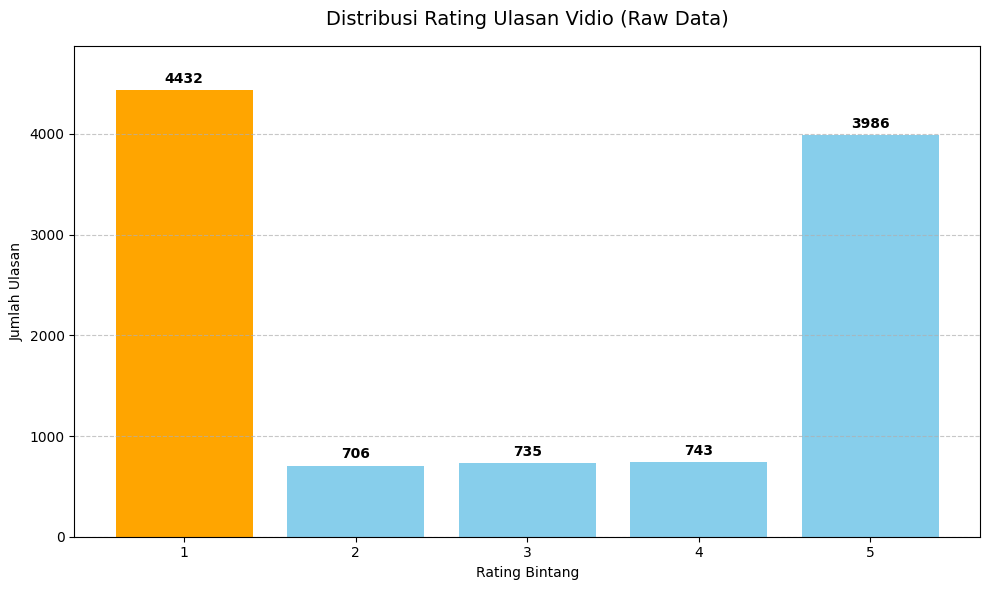


Contoh 5 Data Raw:


,text,rating,date
497,"mau nonton bola malah eror,mending siarin boke...",1,2026-03-31 20:28:46
498,Kntol. Setelah langganan malah jelek kualitas ...,1,2026-03-31 19:45:17
499,VIDEO SPORTS MOVIE SERTS,5,2026-03-31 18:25:53
500,mantap,5,2026-03-31 18:19:48
501,bagussss,5,2026-03-31 15:56:12



========== STATISTIK TERFILTER ==========
Total Data     : 8854
Rentang Tanggal: 2025-04-01 s/d 2026-03-31

Distribusi Rating:
rating
1    4297
2     697
3     701
4     608
5    2551
Name: count, dtype: int64
----------------------------------------
Grafik disimpan di: /content/drive/My Drive/Colab Notebooks/Penelitian/Figures/distribusi_rating_filter.png


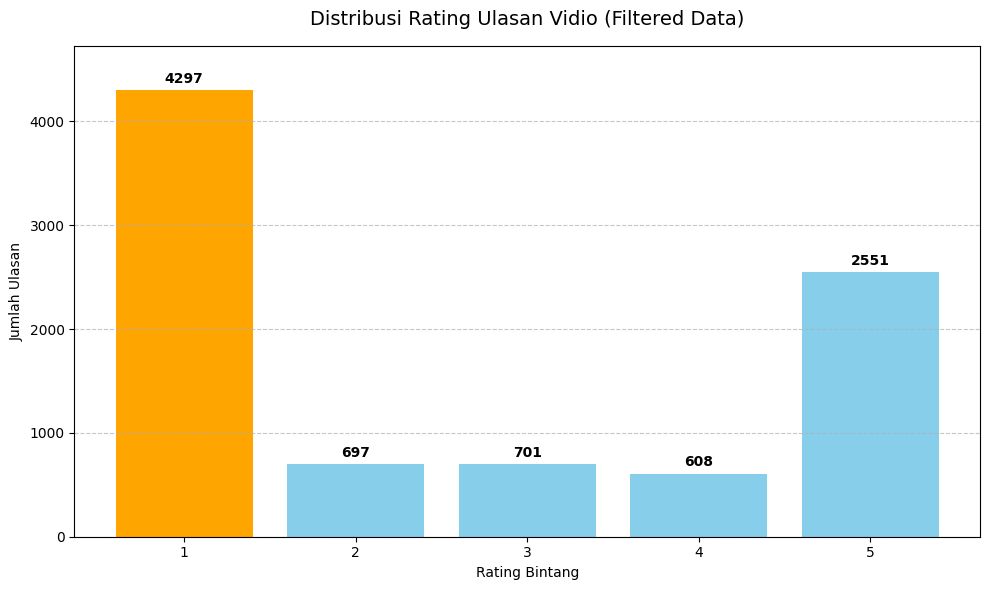


Contoh 5 Data Terfilter:


,text,rating,date
497,"mau nonton bola malah eror,mending siarin boke...",1,2026-03-31 20:28:46
498,Kntol. Setelah langganan malah jelek kualitas ...,1,2026-03-31 19:45:17
499,VIDEO SPORTS MOVIE SERTS,5,2026-03-31 18:25:53
502,min saya pengguna kartu xl dan ada gratis vidi...,5,2026-03-31 15:21:48
503,jujur emng bnyk film tapi ada film kesukaan sy...,2,2026-03-31 12:56:59


In [ ]:
# ==========================================================
# 1. PENGAMBILAN DATA (RAW)
# ==========================================================
app_id = "com.vidio.android"
reviews_raw, _ = reviews(
    app_id,
    lang="id",
    country="id",
    sort=Sort.NEWEST,
    count=15000
)

df_raw = pd.DataFrame(reviews_raw)[["content", "score", "at"]]
df_raw.columns = ["text", "rating", "date"]
df_raw.dropna(inplace=True)
df_raw["date"] = pd.to_datetime(df_raw["date"])

# --- FILTER RENTANG TANGGAL: 2 MEI 2025 – 2 MEI 2026 ---
# Catatan: scraper mengambil by newest, jadi filter ini memastikan cakupan 1 tahun penuh.
start_date = "2025-04-01"
end_date   = "2026-04-01"
df_raw = df_raw[(df_raw["date"] >= start_date) & (df_raw["date"] <= end_date)]
# ---------------------------------------------------------

df_raw.to_csv(BASE_PATH + "data_raw_vidio.csv", index=False)
print_stats(df_raw, "Raw (Filtered by Date)")

# ==========================================================
# 2. VISUALISASI DATA RAW
# ==========================================================
plot_distribution(df_raw, "Distribusi Rating Ulasan Vidio (Raw Data)", "distribusi_rating_raw.png")
print("\nContoh 5 Data Raw:")
display(df_raw.head(5))

# ==========================================================
# 3. FILTERING (HAPUS REVIEW 1 KATA)
# ==========================================================
df_filter = df_raw.copy()
df_filter["word_count"] = df_filter["text"].apply(lambda x: len(str(x).split()))
df_filter = df_filter[df_filter["word_count"] > 1].drop(columns=["word_count"])

df_filter.to_csv(BASE_PATH + "data_filter_vidio.csv", index=False)
print_stats(df_filter, "Terfilter")

# ==========================================================
# 4. VISUALISASI DATA FILTERED
# ==========================================================
plot_distribution(df_filter, "Distribusi Rating Ulasan Vidio (Filtered Data)", "distribusi_rating_filter.png")
print("\nContoh 5 Data Terfilter:")
display(df_filter.head(5))

## 7. Pemrosesan Teks (Text Preprocessing)

In [ ]:
def clean_text_stepwise(text):
    """Pembersihan teks bertahap: case folding → hapus URL → normalisasi slang → kendalikan karakter berulang.
    Menggunakan SLANG_DICT yang sudah dipusatkan di konfigurasi global.
    Catatan: karakter berulang dibatasi maks 2 repetisi (bukan 1) agar tidak memotong
    kata-kata valid seperti 'terlanjur' → penanganan lebih lembut dari regex (.)+.
    """
    # a. Case Folding
    text_cf    = str(text).lower()

    # b. URL Removal
    text_url   = re.sub(r'https?\S+|www\S+', '', text_cf, flags=re.MULTILINE).strip()

    # c. Normalisasi Slang (gunakan kamus terpusat)
    text_slang = " ".join([SLANG_DICT.get(w, w) for w in text_url.split()])

    # d. Pengendalian Karakter Berulang (maks 2 repetisi, konsisten dengan pipeline sentimen)
    text_final = re.sub(r'(.)\1{2,}', r'\1\1', text_slang)

    return pd.Series([text_cf, text_url, text_slang, text_final])


# Siapkan DataFrame dari df_filter hasil cell sebelumnya
df_step = df_filter[["text", "rating", "date"]].copy()
df_step.rename(columns={"text": "original_filter"}, inplace=True)

df_step[["case_folding", "url_removal", "slang_normalization", "repeated_char_removal"]] = \
    df_step["original_filter"].apply(clean_text_stepwise)

# Validasi URL
df_links = df_step[df_step["original_filter"].str.contains(r'http|www', case=False, na=False)]

# Simpan → file ini dipakai oleh cell 8a, 8b, 9a, 9b
df_step.to_csv(BASE_PATH + "data_preprocessed_vidio.csv", index=False)

print("\n" + "="*70)
print(f"{'PEMANTAUAN PROSES PERSIAPAN DATA (STEP-BY-STEP)':^70}")
print("="*70)
pd.set_option("display.max_colwidth", 100)
display(df_step.head(5))

if not df_links.empty:
    print("\nContoh ulasan dengan URL yang berhasil dibersihkan:")
    display(df_links[["original_filter", "url_removal"]].head(3))

print(f"\nData disimpan di: {BASE_PATH}data_preprocessed_vidio.csv")


           PEMANTAUAN PROSES PERSIAPAN DATA (STEP-BY-STEP)            


,original_filter,rating,date,case_folding,url_removal,slang_normalization,repeated_char_removal
497,"mau nonton bola malah eror,mending siarin bokep aja dah",1,2026-03-31 20:28:46,"mau nonton bola malah eror,mending siarin bokep aja dah","mau nonton bola malah eror,mending siarin bokep aja dah","mau nonton bola malah eror,mending siarin bokep aja dah","mau nonton bola malah eror,mending siarin bokep aja dah"
498,"Kntol. Setelah langganan malah jelek kualitas film nya, dan sering lag",1,2026-03-31 19:45:17,"kntol. setelah langganan malah jelek kualitas film nya, dan sering lag","kntol. setelah langganan malah jelek kualitas film nya, dan sering lag","kntol. setelah langganan malah jelek kualitas film nya, dan sering lag","kntol. setelah langganan malah jelek kualitas film nya, dan sering lag"
499,VIDEO SPORTS MOVIE SERTS,5,2026-03-31 18:25:53,video sports movie serts,video sports movie serts,video sports movie serts,video sports movie serts
502,"min saya pengguna kartu xl dan ada gratis vidio tapi gabisa di aktifkan gratis vidionya min, moh...",5,2026-03-31 15:21:48,"min saya pengguna kartu xl dan ada gratis vidio tapi gabisa di aktifkan gratis vidionya min, moh...","min saya pengguna kartu xl dan ada gratis vidio tapi gabisa di aktifkan gratis vidionya min, moh...","min saya pengguna kartu xl dan ada gratis vidio tapi gabisa di aktifkan gratis vidionya min, moh...","min saya pengguna kartu xl dan ada gratis vidio tapi gabisa di aktifkan gratis vidionya min, moh..."
503,jujur emng bnyk film tapi ada film kesukaan sya yang tayang hanya 7 menit yaitu dilan 1990 1991 ...,2,2026-03-31 12:56:59,jujur emng bnyk film tapi ada film kesukaan sya yang tayang hanya 7 menit yaitu dilan 1990 1991 ...,jujur emng bnyk film tapi ada film kesukaan sya yang tayang hanya 7 menit yaitu dilan 1990 1991 ...,jujur emng bnyk film tapi ada film kesukaan sya yang tayang hanya 7 menit yaitu dilan 1990 1991 ...,jujur emng bnyk film tapi ada film kesukaan sya yang tayang hanya 7 menit yaitu dilan 1990 1991 ...



Contoh ulasan dengan URL yang berhasil dibersihkan:


,original_filter,url_removal
3646,Wowww Like Vidio,wowww like vidio
9793,nih npa dah kan gw langganan sebulan yg 16 rebu dari Telkomsel di tanggal 30 April 2025 kan atur...,nih npa dah kan gw langganan sebulan yg 16 rebu dari telkomsel di tanggal 30 april 2025 kan atur...



Data disimpan di: /content/drive/My Drive/Colab Notebooks/Penelitian/data_preprocessed_vidio.csv


## 8. Topic Modeling BERTopic

### 8a. Baseline BERTopic

In [ ]:
# Load data preprocessed
df = pd.read_csv(BASE_PATH + "data_preprocessed_vidio.csv")
df["clean_base_bertopic_baseline"] = df["repeated_char_removal"].astype(str)

# Model Baseline (parameter default)
embedding_model_base = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
topic_model_baseline = BERTopic(embedding_model=embedding_model_base, verbose=True)

topics_base, _ = topic_model_baseline.fit_transform(df["clean_base_bertopic_baseline"])
df["topic_baseline"] = topics_base

print("### INFO TOPIK BASELINE")
display(topic_model_baseline.get_topic_info().head(10))

# Coherence Score Baseline
texts_tok_base = [doc.split() for doc in df["clean_base_bertopic_baseline"]]
dict_base      = Dictionary(texts_tok_base)
score_base     = compute_coherence(topic_model_baseline, texts_tok_base, dict_base, is_ngram=False)
print(f"\nBaseline Coherence Score (C_V): {score_base:.4f}" if score_base else "Coherence tidak dapat dihitung.")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

Batches:   0%|          | 0/277 [00:00<?, ?it/s]

2026-04-27 00:39:11,613 - BERTopic - Embedding - Completed ✓
2026-04-27 00:39:11,617 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-04-27 00:40:07,395 - BERTopic - Dimensionality - Completed ✓
2026-04-27 00:40:07,396 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-04-27 00:40:07,707 - BERTopic - Cluster - Completed ✓
2026-04-27 00:40:07,714 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-04-27 00:40:07,881 - BERTopic - Representation - Completed ✓


### INFO TOPIK BASELINE


,Topic,Count,Name,Representation,Representative_Docs
0,-1,2882,-1_di_tidak_iklan_nonton,"[di, tidak, iklan, nonton, sudah, ada, nya, yang, langganan, vidio]","[saya langganan aplikasi ini, tapi ketika mau bayar langganan bulan lalu dan bulan ini, pakai pu..."
1,0,267,0_bola_liga_league_inggris,"[bola, liga, league, inggris, premier, pertandingan, sepak, nonton, sport, live]","[sangat bagus kalau nonton bola, aplikasi bagus buat nonton bola, nonton bola]"
2,1,248,1_platinum_paket_beli_extra,"[platinum, paket, beli, extra, saya, sudah, aktif, belum, mahasiswa, bisa]","[bagus sekali tapi harus beli platinum, tolong perbaiki bug paket platinum nya, saya beli lewat ..."
3,2,221,2_aplikasinya_bagus_aplikasi_sangat,"[aplikasinya, bagus, aplikasi, sangat, suka, keren, ini, banget, membantu, app]","[aplikasinya sangat bagus, aplikasinya sangat bagus😊, aplikasinya sangat bagus saya suka]"
4,3,218,3_aplikasi_buruk_guna_jelas,"[aplikasi, buruk, guna, jelas, tolol, aplikasinya, app, tidak, ini, error]","[aplikasi tidak jelas, kenapa aplikasi nya tidak bisa di buka ?, menurutku tontonan aplikasi ini..."
5,4,218,4_aplikasi_dana_saldo_tiba,"[aplikasi, dana, saldo, tiba, tanpa, uang, ini, otomatis, bayar, saya]","[aplikasi ini tiba tiba mengambil dana saya tanpa sepengetahuan saya, aneh orang sudah hapus apl..."
6,5,205,5_bagus_good_baguss_oke,"[bagus, good, baguss, oke, sangat, baik, sagat, lumayan, so, sekali]","[bagus 👍👍, bagus 👍👍, bagus 👍👍]"
7,6,160,6_vidio_video_suka_jernih,"[vidio, video, suka, jernih, gambar, vidionya, keren, terimakasih, bagus, aku]","[saya suka vidio, aku suka nonton film di vidio, bagus banget aku suka banget nonton di vidio]"
8,7,130,7_beli_paket_paketan_paketnya,"[beli, paket, paketan, paketnya, pulsa, sudah, bisa, tidak, tapi, aktif]","[aku beli paket kenapa tidak bisa?, dari awal langganan aman aja, tapi bulan ini paket langganan..."
9,8,128,8_iklan_iklannya_aplikasi_banyak,"[iklan, iklannya, aplikasi, banyak, ini, isinya, terlalu, muncul, kebanyakan, dari]","[sudah iklannya bejibun, aplikasi nya berat dan baru nonton sebentar sudah muncul iklan lagi. be..."



Baseline Coherence Score (C_V): 0.4072


### 8b. Optimasi BERTopic

In [ ]:
# Load data preprocessed
df = pd.read_csv(BASE_PATH + "data_preprocessed_vidio.csv")
df["clean_base_bertopic"] = df["repeated_char_removal"].astype(str)

# Stopwords gabungan Sastrawi + custom
factory_sw         = StopWordRemoverFactory()
stopwords_sastrawi = set(factory_sw.get_stop_words())
custom_stopwords   = {
    "video", "tonton", "aplikasi", "vidio", "nya", "banget", "sih", "dong",
    "nih", "ya", "aja", "the", "best", "good", "job", "aku", "kok", "gak",
    "mau", "terus", "malah", "ni", "apk", "udh", "sama", "sekali", "si", "pencari", "tuhan"
}
ALL_STOPWORDS = list(stopwords_sastrawi.union(custom_stopwords))

# Encode embeddings — dibuat sekali, dipakai di cell 8b dan 8c
embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
embeddings = embedding_model.encode(
    df["clean_base_bertopic"].tolist(),
    show_progress_bar=True
)

# Komponen BERTopic
# Catatan: UMAP menggunakan metric cosine, HDBSCAN juga cosine agar konsisten
umap_model       = UMAP(n_neighbors=50, n_components=10, min_dist=0.1, metric="cosine", random_state=SEED)
hdbscan_model    = HDBSCAN(min_cluster_size=30, min_samples=10, metric="euclidean",
                            cluster_selection_method="eom", prediction_data=True)
vectorizer_model = CountVectorizer(ngram_range=(2, 3), min_df=2, max_df=0.5, stop_words=ALL_STOPWORDS)
ctfidf_model     = ClassTfidfTransformer(reduce_frequent_words=True)

topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    ctfidf_model=ctfidf_model,
    nr_topics="auto"
)

topics, _ = topic_model.fit_transform(df["clean_base_bertopic"], embeddings)
df["topic"] = topics

# Coherence Score Optimasi
texts_tok  = [doc.split() for doc in df["clean_base_bertopic"]]
dictionary = Dictionary(texts_tok)
score_opt  = compute_coherence(topic_model, texts_tok, dictionary, is_ngram=True)
print(f"Optimasi Coherence Score (C_V): {score_opt:.4f}" if score_opt else "Coherence tidak dapat dihitung.")

df.to_csv(BASE_PATH + "Optimasi_BERTopic_vidio.csv", index=False)
print(f"File disimpan di: {BASE_PATH}Optimasi_BERTopic_vidio.csv")

# Simpan model (untuk fallback di cell Integrasi jika Colab disconnect)
topic_model.save(BASE_PATH + "topic_model_saved")
print(f"Model BERTopic disimpan di: {BASE_PATH}topic_model_saved")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/277 [00:00<?, ?it/s]

Optimasi Coherence Score (C_V): 0.6878


2026-04-27 00:41:09,310 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


File disimpan di: /content/drive/My Drive/Colab Notebooks/Penelitian/Optimasi_BERTopic_vidio.csv
Model BERTopic disimpan di: /content/drive/My Drive/Colab Notebooks/Penelitian/topic_model_saved


### 8c. Reduksi Topik & Visualisasi BERTopic

In [ ]:
topic_model.reduce_topics(df["clean_base_bertopic"], nr_topics=8)
df["topic"] = topic_model.topics_

# Update CSV dengan topik pasca-reduksi
# (PENTING: cell Integrasi memuat file ini, harus berisi topik pasca-reduksi)
df.to_csv(BASE_PATH + "Optimasi_BERTopic_vidio.csv", index=False)
print("CSV Optimasi_BERTopic_vidio.csv diperbarui dengan topik pasca-reduksi.")

print("\nTopik setelah reduksi:")
display(topic_model.get_topic_info())

CSV Optimasi_BERTopic_vidio.csv diperbarui dengan topik pasca-reduksi.

Topik setelah reduksi:


,Topic,Count,Name,Representation,Representative_Docs
0,-1,2311,-1_google play_suruh beli_live streaming_saldo google play,"[google play, suruh beli, live streaming, saldo google play, saldo google, bayar langganan, siny...",[kenapa ya setiap kali saya mau nonton di vidio nonton tv di live kenapa sering loading mulu ya ...
1,0,3917,0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,"[kebanyakan iklan, terlalu banyak iklan, nonton iklan, banyak iklannya, iklan banyak, saldo dana...","[bayar mahal2 tiap bulan.. pas nonton iklan mulu tiap 5 menit.., bagus ya awal awal nonton seru ..."
2,1,1834,1_sangat bagus_sangat baik_bagus sangat_premier league,"[sangat bagus, sangat baik, bagus sangat, premier league, sangat puas, sangat memuaskan, bagus s...",[duh kurang aja banget ni aplikasi maen ambil aja pulsa orang..pantesan setiap bulan kan gua isi...
3,2,380,2_film film_film terbaru_drama korea_liga indonesia,"[film film, film terbaru, drama korea, liga indonesia, banyak film, tv indonesia, update film, f...",[lumayan bisa nonton acara apa yang aku suka menurut ku oke lah mohon maaf bukannya menghina tap...
4,3,245,3_paket platinum_langganan platinum_platinum extra_berlangganan platinum,"[paket platinum, langganan platinum, platinum extra, berlangganan platinum, platinum nonton, lan...","[nyesel beli paket langganan di sini. di paket platinum biasa tertulis bisa nonton tayangan bwf,..."
5,4,82,4_nomor hp_no hp_login pake_pake no hp,"[nomor hp, no hp, login pake, pake no hp, pake no, nomer hp, pake nomor hp, pake nomor, login pa...","[tidak bisa login pake no hp, ini kenapa gabisa login lewat nomor hp , malah suruh pake gogle al..."
6,5,48,5_ukuran subtitle_fitur download_besar kecil_dulu download,"[ukuran subtitle, fitur download, besar kecil, dulu download, kurang nyaman, hasil download, ber...","[mini dramanya bagus, tapi subtitle inggris harus ditekan ulang tiap ganti episode. sangat tidak..."
7,6,37,6_cenel rcti_nonton rcti_channel tv_bagus cuman kalau,"[cenel rcti, nonton rcti, channel tv, bagus cuman kalau, kan sayang, bola tiba2, bagus siaran, l...","[sudah bela belain berlangganan buat nonton rcti ternyata persibnya tidak di tayangin👎🏻, kecewa ..."


In [ ]:
topic_model.visualize_topics()

In [ ]:
topic_model.visualize_barchart(top_n_topics=15)

In [ ]:
topic_model.visualize_hierarchy()

In [ ]:
# embeddings masih tersedia dari cell 8b (run berurutan)
topic_model.visualize_documents(df["clean_base_bertopic"].tolist(), embeddings=embeddings)

## 9. Analisis Sentimen

### 9a. Baseline Sentimen

In [ ]:
# 1. Load data preprocessed
df_base = pd.read_csv(BASE_PATH + "data_preprocessed_vidio.csv")
df_base["text_baseline_sentiment"] = df_base["repeated_char_removal"].astype(str)

# 2. Actual label menggunakan fungsi 3-kelas (termasuk neutral)
df_base["actual_label"] = df_base["rating"].apply(map_rating_to_label)

# 3. Auto-detect device (GPU jika tersedia, CPU jika tidak)
device = 0 if torch.cuda.is_available() else -1
print(f"Device yang digunakan: {'GPU (cuda)' if device == 0 else 'CPU'}")

print("Memuat Baseline Model: w11wo/indonesian-roberta-base-sentiment-classifier...")
baseline_sentiment_pipe = pipeline(
    "text-classification",
    model="w11wo/indonesian-roberta-base-sentiment-classifier",
    tokenizer="w11wo/indonesian-roberta-base-sentiment-classifier",
    max_length=512,
    truncation=True,
    device=device
)

print("Memulai proses prediksi baseline...")
results_base = baseline_sentiment_pipe(df_base["text_baseline_sentiment"].tolist(), batch_size=64)

# Normalisasi label dari model ke lowercase (misal: "Positive" -> "positive")
df_base["pred_label_baseline"] = [res["label"].lower() for res in results_base]

# Validasi label — memastikan output model sesuai
labels_found = df_base["pred_label_baseline"].unique()
print("Label unik dari model:", labels_found)

# ─── EVALUASI: 3-KELAS ───────────────────────────────────────────────────────
f1_baseline = f1_score(
    df_base["actual_label"],
    df_base["pred_label_baseline"],
    average="weighted",
    zero_division=0
)

print("\n" + "="*60)
print(f"{'HASIL ANALISIS SENTIMEN BASELINE (3 KELAS)':^60}")
print("="*60)
print(f"Weighted F1-Score Baseline (Termasuk Neutral): {f1_baseline:.4f}")
print("-" * 60)
print(classification_report(
    df_base["actual_label"],
    df_base["pred_label_baseline"],
    zero_division=0
))

df_base.to_csv(BASE_PATH + "data_baseline_sentiment.csv", index=False)
print(f"Disimpan di: {BASE_PATH}data_baseline_sentiment.csv")


Device yang digunakan: GPU (cuda)
Memuat Baseline Model: w11wo/indonesian-roberta-base-sentiment-classifier...


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: w11wo/indonesian-roberta-base-sentiment-classifier
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Memulai proses prediksi baseline...
Label unik dari model: ['negative' 'neutral' 'positive']

         HASIL ANALISIS SENTIMEN BASELINE (3 KELAS)         
Weighted F1-Score Baseline (Termasuk Neutral): 0.7192
------------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.75      0.90      0.82      4994
     neutral       0.09      0.10      0.09       701
    positive       0.90      0.58      0.71      3159

    accuracy                           0.72      8854
   macro avg       0.58      0.53      0.54      8854
weighted avg       0.75      0.72      0.72      8854

Disimpan di: /content/drive/My Drive/Colab Notebooks/Penelitian/data_baseline_sentiment.csv


In [ ]:
print("### 5 Topik Teratas dengan Rasio Negatif Tertinggi dari Sentiment Analysis")
display(top_issues.head(5))

### 5 Topik Teratas dengan Rasio Negatif Tertinggi dari Sentiment Analysis


pred_label_baseline,negative,neutral,positive,negative_ratio
topic_name,,,,
5_ukuran subtitle_fitur download_besar kecil_dulu download,44,2,2,0.916667
4_nomor hp_no hp_login pake_pake no hp,71,11,0,0.865854
3_paket platinum_langganan platinum_platinum extra_berlangganan platinum,212,26,7,0.865306
6_cenel rcti_nonton rcti_channel tv_bagus cuman kalau,28,9,0,0.756757
0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,3584,613,749,0.724626


In [ ]:
display(df_base.tail(5))

,original_filter,rating,date,case_folding,url_removal,slang_normalization,repeated_char_removal,text_baseline_sentiment,actual_label,pred_label_baseline
8849,bagus tapi siaran RCTI nya tidak ada,4,2025-04-01 07:14:29,bagus tapi siaran rcti nya tidak ada,bagus tapi siaran rcti nya tidak ada,bagus tapi siaran rcti nya tidak ada,bagus tapi siaran rcti nya tidak ada,bagus tapi siaran rcti nya tidak ada,positive,negative
8850,Terimakasih untuk yang membuat aplikasi vidio ini The best pisan,5,2025-04-01 07:07:35,terimakasih untuk yang membuat aplikasi vidio ini the best pisan,terimakasih untuk yang membuat aplikasi vidio ini the best pisan,terimakasih untuk yang membuat aplikasi vidio ini the best pisan,terimakasih untuk yang membuat aplikasi vidio ini the best pisan,terimakasih untuk yang membuat aplikasi vidio ini the best pisan,positive,positive
8851,"coba aja nggk ada vidio premium,pasti saya nonton terus dramanya,kenapa harus ada pembayaran sih...",1,2025-04-01 06:52:52,"coba aja nggk ada vidio premium,pasti saya nonton terus dramanya,kenapa harus ada pembayaran sih...","coba aja nggk ada vidio premium,pasti saya nonton terus dramanya,kenapa harus ada pembayaran sih...","coba aja nggk ada vidio premium,pasti saya nonton terus dramanya,kenapa harus ada pembayaran sih...","coba aja nggk ada vidio premium,pasti saya nonton terus dramanya,kenapa harus ada pembayaran sih...","coba aja nggk ada vidio premium,pasti saya nonton terus dramanya,kenapa harus ada pembayaran sih...",negative,negative
8852,aplikasi video ini seru karena bisa nonton apa saja dan murah,5,2025-04-01 04:24:00,aplikasi video ini seru karena bisa nonton apa saja dan murah,aplikasi video ini seru karena bisa nonton apa saja dan murah,aplikasi video ini seru karena bisa nonton apa saja dan murah,aplikasi video ini seru karena bisa nonton apa saja dan murah,aplikasi video ini seru karena bisa nonton apa saja dan murah,positive,positive
8853,burik kli nih apk mangkin lama mau nyari untung aja main sedot saldo orng sembarangan padhl udh ...,1,2025-04-01 00:28:20,burik kli nih apk mangkin lama mau nyari untung aja main sedot saldo orng sembarangan padhl udh ...,burik kli nih apk mangkin lama mau nyari untung aja main sedot saldo orng sembarangan padhl udh ...,burik kli nih aplikasi mangkin lama mau nyari untung aja main sedot saldo orng sembarangan padhl...,burik kli nih aplikasi mangkin lama mau nyari untung aja main sedot saldo orng sembarangan padhl...,burik kli nih aplikasi mangkin lama mau nyari untung aja main sedot saldo orng sembarangan padhl...,negative,negative


## 10. Integrasi BERTopic & Sentimen

In [ ]:
# Load hasil dua pipeline
# Optimasi_BERTopic_vidio.csv → sudah diupdate dengan topik pasca-reduksi (cell 8c)
# Optimasi_Sentiment_vidio.csv → hasil optimasi sentimen 3-kelas (cell 9b)
df_topic     = pd.read_csv(BASE_PATH + "Optimasi_BERTopic_vidio.csv")
df_sentiment = pd.read_csv(BASE_PATH + "data_baseline_sentiment.csv")

# Merge berdasarkan teks ulasan asli
# Catatan: df_sentiment sekarang berisi SEMUA rating (termasuk rating 3),
# sehingga left join tidak akan menghasilkan NaN pred_label untuk rating 3.
df_integrated = df_topic.merge(
    df_sentiment[["original_filter", "pred_label_baseline", "text_baseline_sentiment", "actual_label"]],
    on="original_filter",
    how="inner"   # inner join: hanya baris dengan pasangan di kedua file
)

# Cek dan hapus sisa NaN pada pred_label jika ada
nan_count = df_integrated["pred_label_baseline"].isna().sum()
if nan_count > 0:
    print(f"[WARNING] Ditemukan {nan_count} baris NaN pada pred_label. Baris ini akan dihapus.")
    df_integrated = df_integrated.dropna(subset=["pred_label_baseline"]).reset_index(drop=True)

# Load model BERTopic (dari file jika variabel hilang karena disconnect)
try:
    _ = topic_model  # cek apakah masih ada di memori
except NameError:
    print("Variabel topic_model tidak ditemukan, memuat ulang dari disk...")
    topic_model = BERTopic.load(BASE_PATH + "topic_model_saved")
    print("Model berhasil dimuat.")

# Mapping nama topik
topic_names = topic_model.get_topic_info().set_index("Topic")["Name"].to_dict()
df_integrated["topic_name"] = df_integrated["topic"].map(topic_names)

# Hapus outlier BERTopic (topic = -1) dari analisis insight
df_integrated_clean = df_integrated[df_integrated["topic"] != -1].copy()
print(f"[INFO] Jumlah data setelah hapus outlier topik (-1): {len(df_integrated_clean)} dari {len(df_integrated)}")

# Insight distribusi sentimen per topik (tanpa outlier)
insight = df_integrated_clean.groupby(["topic_name", "pred_label_baseline"]).size().unstack(fill_value=0)
if not insight.empty:
    insight["Total"] = insight.sum(axis=1)
    insight = insight.sort_values(by="Total", ascending=False)

print("\n### TABEL INSIGHT: DISTRIBUSI SENTIMEN PER TOPIK")
display(insight)

print("\n### CONTOH DATA HASIL INTEGRASI")
example_table = df_integrated_clean.groupby(["topic_name", "pred_label_baseline"]).head(1)
display(example_table[["topic_name", "pred_label_baseline", "original_filter"]].head(10))

# Simpan
output_file = BASE_PATH + "Integrasi_aplikasi_vidio.csv"
df_integrated.to_csv(output_file, index=False)
print(f"\n[INFO] Data integrasi disimpan di: {output_file}")

[INFO] Jumlah data setelah hapus outlier topik (-1): 12048 dari 14714

### TABEL INSIGHT: DISTRIBUSI SENTIMEN PER TOPIK


pred_label_baseline,negative,neutral,positive,Total
topic_name,,,,
1_sangat bagus_sangat baik_bagus sangat_premier league,982,165,5161,6308
0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,3584,613,749,4946
2_film film_film terbaru_drama korea_liga indonesia,215,38,129,382
3_paket platinum_langganan platinum_platinum extra_berlangganan platinum,212,26,7,245
4_nomor hp_no hp_login pake_pake no hp,71,11,0,82
5_ukuran subtitle_fitur download_besar kecil_dulu download,44,2,2,48
6_cenel rcti_nonton rcti_channel tv_bagus cuman kalau,28,9,0,37



### CONTOH DATA HASIL INTEGRASI


,topic_name,pred_label_baseline,original_filter
0,1_sangat bagus_sangat baik_bagus sangat_premier league,negative,"mau nonton bola malah eror,mending siarin bokep aja dah"
1,2_film film_film terbaru_drama korea_liga indonesia,negative,"Kntol. Setelah langganan malah jelek kualitas film nya, dan sering lag"
2,0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,neutral,VIDEO SPORTS MOVIE SERTS
5,0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,positive,"suka sama siaran nya,tolong klo bisa lebih jernih lagi deh gambar nya"
6,0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,negative,"sampah & ribet, banyak iklan padahal sudah langganan"
8,1_sangat bagus_sangat baik_bagus sangat_premier league,neutral,akula van
31,1_sangat bagus_sangat baik_bagus sangat_premier league,positive,aplikasinya bagus...🥰🥰🙏🙏.
77,4_nomor hp_no hp_login pake_pake no hp,negative,"ini kenapa ngak bisa verifikasi nomor HP, padahal sudah ada tulisan terverifikasi di keterangan ..."
89,2_film film_film terbaru_drama korea_liga indonesia,positive,min tolong dong tanyangin film beauty and the best maxsim bouttier pengen banget nonton🙏🙏🙏
107,3_paket platinum_langganan platinum_platinum extra_berlangganan platinum,negative,ini ko saya udah membayar platinum mahasiswa tapi masih belum ke buka gimana yah 🙂‍↕️?



[INFO] Data integrasi disimpan di: /content/drive/My Drive/Colab Notebooks/Penelitian/Integrasi_aplikasi_vidio.csv


## 11. Evaluasi Statistik

In [ ]:
# Gunakan df_integrated_clean (sudah bebas outlier topik -1 dan NaN)
sentiment_map = {"negative": 0, "neutral": 1, "positive": 2}
df_stat = df_integrated_clean.copy()
df_stat["sentiment_code"] = df_stat["pred_label_baseline"].map(sentiment_map)

# Hapus baris dengan sentiment_code NaN (label di luar {negative, neutral, positive})
df_stat = df_stat.dropna(subset=["sentiment_code", "rating"]).copy()
df_stat["sentiment_code"] = df_stat["sentiment_code"].astype(int)

# 1. SPEARMAN RANK CORRELATION
coef, p_spearman = spearmanr(df_stat["rating"], df_stat["sentiment_code"])

print("### HASIL UJI SPEARMAN RANK CORRELATION")
print(f"Koefisien Korelasi: {coef:.4f}")
print(f"P-Value           : {p_spearman:.4e}")
print("Kesimpulan:", "Terdapat hubungan signifikan (p < 0.05)." if p_spearman < 0.05
      else "Tidak terdapat hubungan signifikan.")
print("-" * 50)

# 2. KRUSKAL-WALLIS TEST
# Filter group yang memiliki lebih dari 1 anggota agar tidak crash
groups = [
    g["sentiment_code"].values
    for _, g in df_stat.groupby("topic_name")
    if len(g) > 1
]
if len(groups) >= 2:
    stat_h, p_kruskal = kruskal(*groups)
    print("### HASIL UJI KRUSKAL-WALLIS")
    print(f"Statistik H: {stat_h:.4f}")
    print(f"P-Value    : {p_kruskal:.4e}")
    print("Kesimpulan:", "Terdapat perbedaan distribusi signifikan antar topik."
          if p_kruskal < 0.05 else "Tidak terdapat perbedaan distribusi signifikan antar topik.")
else:
    print("Kruskal-Wallis tidak dapat dijalankan: jumlah group valid < 2.")

# 3. MEDIAN PER TOPIK
print("\n### MEDIAN SENTIMEN PER TOPIK")
median_per_topic = (df_stat.groupby("topic_name")["sentiment_code"]
                    .median().sort_values(ascending=False))
print(median_per_topic)

### HASIL UJI SPEARMAN RANK CORRELATION
Koefisien Korelasi: 0.7910
P-Value           : 0.0000e+00
Kesimpulan: Terdapat hubungan signifikan (p < 0.05).
--------------------------------------------------
### HASIL UJI KRUSKAL-WALLIS
Statistik H: 5072.0662
P-Value    : 0.0000e+00
Kesimpulan: Terdapat perbedaan distribusi signifikan antar topik.

### MEDIAN SENTIMEN PER TOPIK
topic_name
1_sangat bagus_sangat baik_bagus sangat_premier league                      2.0
0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya        0.0
2_film film_film terbaru_drama korea_liga indonesia                         0.0
3_paket platinum_langganan platinum_platinum extra_berlangganan platinum    0.0
4_nomor hp_no hp_login pake_pake no hp                                      0.0
5_ukuran subtitle_fitur download_besar kecil_dulu download                  0.0
6_cenel rcti_nonton rcti_channel tv_bagus cuman kalau                       0.0
Name: sentiment_code, dtype: float64


## 12. Visualisasi & Interpretasi

In [ ]:
# Tampilkan 5 contoh data integrasi
print("### CONTOH 5 DATA HASIL INTEGRASI")
display(df_integrated_clean[["topic_name", "original_filter", "pred_label_baseline", "rating"]].head(5))

### CONTOH 5 DATA HASIL INTEGRASI


,topic_name,original_filter,pred_label_baseline,rating
0,1_sangat bagus_sangat baik_bagus sangat_premier league,"mau nonton bola malah eror,mending siarin bokep aja dah",negative,1
1,2_film film_film terbaru_drama korea_liga indonesia,"Kntol. Setelah langganan malah jelek kualitas film nya, dan sering lag",negative,1
2,0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,VIDEO SPORTS MOVIE SERTS,neutral,5
4,2_film film_film terbaru_drama korea_liga indonesia,jujur emng bnyk film tapi ada film kesukaan sya yang tayang hanya 7 menit yaitu dilan 1990 1991 ...,negative,2
5,0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,"suka sama siaran nya,tolong klo bisa lebih jernih lagi deh gambar nya",positive,5


In [ ]:
print("### CONTOH 3 ULASAN PER TOPIK DENGAN SENTIMEN ANALISIS")

for topic_name in sorted(df_integrated_clean['topic_name'].unique()):
    if pd.isna(topic_name):
        continue
    topic_df = df_integrated_clean[df_integrated_clean['topic_name'] == topic_name]
    sampled_reviews = topic_df.sample(min(3, len(topic_df)), random_state=SEED)

    print(f"\n--- Topik: {topic_name} ---")
    display(sampled_reviews[['topic_name', 'original_filter', 'pred_label_baseline']])

### CONTOH 3 ULASAN PER TOPIK DENGAN SENTIMEN ANALISIS

--- Topik: 0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya ---


,topic_name,original_filter,pred_label_baseline
320,0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,"JELEK IKLAN MULU PADAHAL PREMIUM, TRUS USER INTERFACE NYA GAMPANG KELUAR APLIKASI",negative
1900,0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,"Aplikasi yang sangat mendukung untuk yang belum bisa nonton secara live,bisa di tonton dengan fl...",positive
1478,0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,vidio ini skrg knpa ya ga bisa di buka,negative



--- Topik: 1_sangat bagus_sangat baik_bagus sangat_premier league ---


,topic_name,original_filter,pred_label_baseline
4611,1_sangat bagus_sangat baik_bagus sangat_premier league,Lumayan bagüsz..,positive
1046,1_sangat bagus_sangat baik_bagus sangat_premier league,bagus y,positive
3836,1_sangat bagus_sangat baik_bagus sangat_premier league,sangat bagus,positive



--- Topik: 2_film film_film terbaru_drama korea_liga indonesia ---


...

,topic_name,original_filter,pred_label_baseline
9370,4_nomor hp_no hp_login pake_pake no hp,izinkan hp SS doonk,neutral
77,4_nomor hp_no hp_login pake_pake no hp,"ini kenapa ngak bisa verifikasi nomor HP, padahal sudah ada tulisan terverifikasi di keterangan ...",negative
5369,4_nomor hp_no hp_login pake_pake no hp,kenapa sih gak bisa daftar pake nomor hp padahal udh langganan lewat nomor hp,negative



--- Topik: 5_ukuran subtitle_fitur download_besar kecil_dulu download ---


,topic_name,original_filter,pred_label_baseline
10541,5_ukuran subtitle_fitur download_besar kecil_dulu download,"sangat kurang nyaman dalam menonton krn ukuran Subtitle terlalu besar, sekiranya bisa di buat kn...",negative
12359,5_ukuran subtitle_fitur download_besar kecil_dulu download,tolong diperbaiki subtitlenya. kadang ukuran fontnya berubah dari kecil ke besar saat melihat no...,negative
10536,5_ukuran subtitle_fitur download_besar kecil_dulu download,ini cara setting ukuran subtitle nya gimana ya? kok jadi gede banget pas nonton. jadi ga enak ma...,negative



--- Topik: 6_cenel rcti_nonton rcti_channel tv_bagus cuman kalau ---


,topic_name,original_filter,pred_label_baseline
10905,6_cenel rcti_nonton rcti_channel tv_bagus cuman kalau,sayangnya RCTI tidk ada..😔😔,negative
6316,6_cenel rcti_nonton rcti_channel tv_bagus cuman kalau,knp rcti nggk ada di vidio ya?,negative
1160,6_cenel rcti_nonton rcti_channel tv_bagus cuman kalau,udh berlangganan gak muncul tayangannya RCTI kocak,negative


### DISTRIBUSI SENTIMEN KESELURUHAN


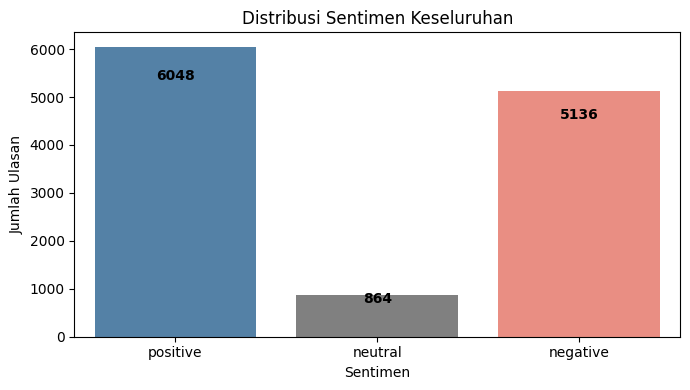

In [ ]:
# ── Distribusi Sentimen Keseluruhan ─────────────────────────────────────────
print("### DISTRIBUSI SENTIMEN KESELURUHAN")

plt.figure(figsize=(7, 4))
order  = ["positive", "neutral", "negative"]
colors = ["steelblue", "gray", "salmon"]
ax = sns.countplot(
    data=df_integrated_clean,
    x="pred_label_baseline",
    order=[o for o in order if o in df_integrated_clean["pred_label_baseline"].unique()],
    palette=dict(zip(order, colors))
)

for container in ax.containers:
    for bar in container:
        height = bar.get_height()
        if height > 0:
            ax.text(bar.get_x() + bar.get_width() / 2.,
                    height - (height * 0.1),
                    f'{int(height)}',
                    ha='center', va='center',
                    color='black', fontweight='bold')

plt.title("Distribusi Sentimen Keseluruhan")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah Ulasan")
plt.tight_layout()
plt.savefig(FIGURES_PATH + "distribusi_sentimen_overall.png", dpi=300, bbox_inches="tight")
plt.show()


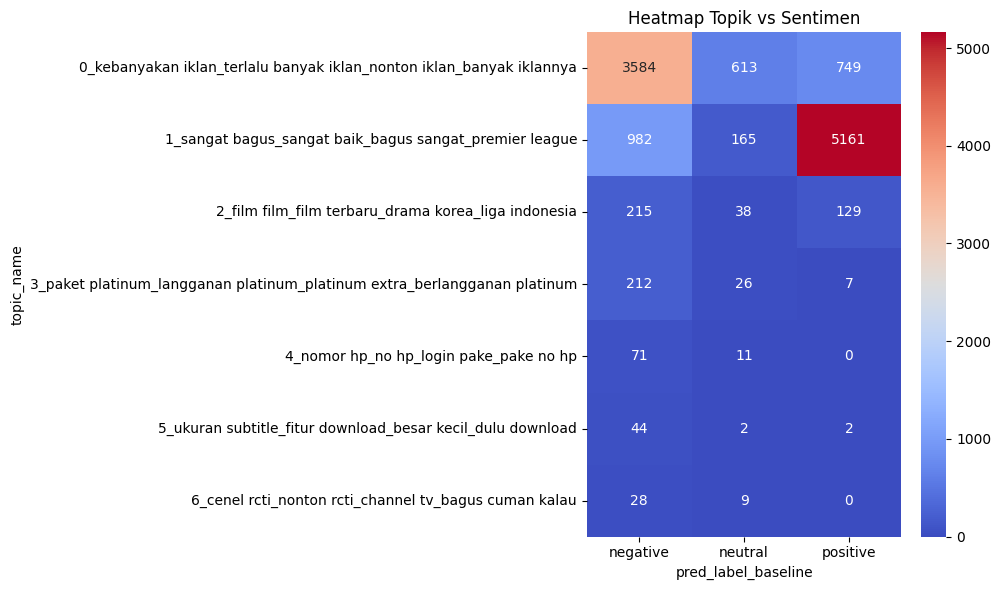

In [ ]:
# ── Heatmap Topik vs Sentimen ────────────────────────────────────────────────
plt.figure(figsize=(10, 6))
sns.heatmap(sent_topic, annot=True, fmt="d", cmap="coolwarm")
plt.title("Heatmap Topik vs Sentimen")
plt.tight_layout()
plt.savefig(FIGURES_PATH + "heatmap_topik_sentimen.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# ── Top Issues (negative ratio tertinggi) ────────────────────────────────────
sent_topic_analysis = sent_topic.copy()
total_cols = [c for c in ["negative", "neutral", "positive"] if c in sent_topic_analysis.columns]
sent_topic_analysis["negative_ratio"] = (
    sent_topic_analysis.get("negative", pd.Series(0, index=sent_topic_analysis.index)) /
    sent_topic_analysis[total_cols].sum(axis=1)
)
top_issues = sent_topic_analysis.sort_values(by="negative_ratio", ascending=False)
print("### TOP ISSUES (Topik dengan Negative Ratio Tertinggi)")
display(top_issues.head(10))

### TOP ISSUES (Topik dengan Negative Ratio Tertinggi)


pred_label_baseline,negative,neutral,positive,negative_ratio
topic_name,,,,
5_ukuran subtitle_fitur download_besar kecil_dulu download,44,2,2,0.916667
4_nomor hp_no hp_login pake_pake no hp,71,11,0,0.865854
3_paket platinum_langganan platinum_platinum extra_berlangganan platinum,212,26,7,0.865306
6_cenel rcti_nonton rcti_channel tv_bagus cuman kalau,28,9,0,0.756757
0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,3584,613,749,0.724626
2_film film_film terbaru_drama korea_liga indonesia,215,38,129,0.562827
1_sangat bagus_sangat baik_bagus sangat_premier league,982,165,5161,0.155675


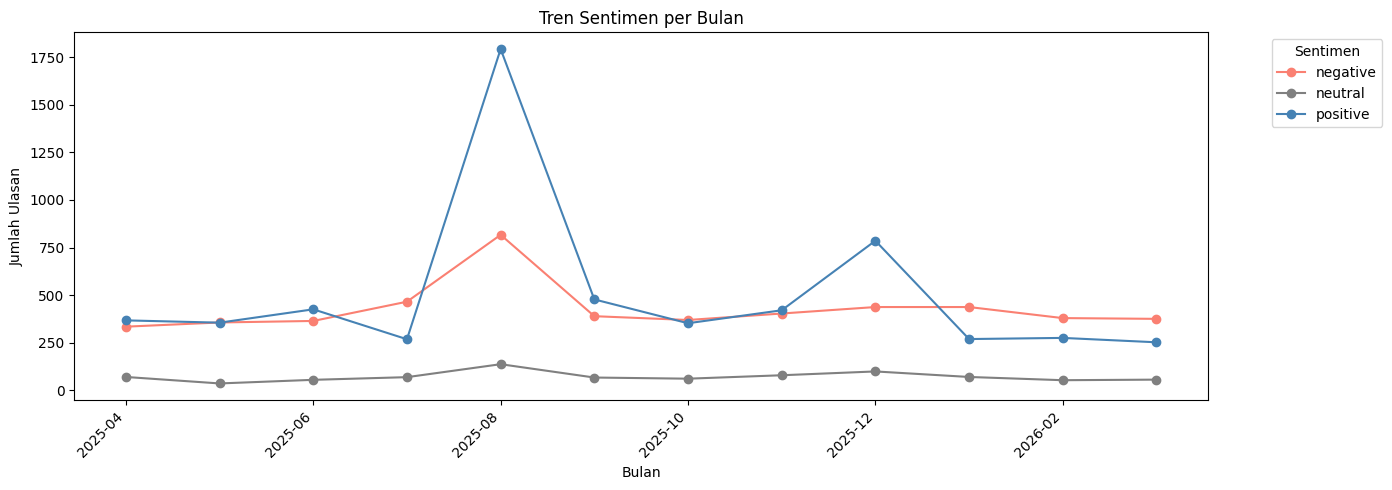

In [ ]:
# ── Tren Sentimen per Bulan (time series) ────────────────────────────────────
# Kolom date tersedia di df_integrated_clean karena diambil dari df_step
df_ts = df_integrated_clean.copy()
df_ts["date"] = pd.to_datetime(df_ts["date"])
df_ts["month"] = df_ts["date"].dt.to_period("M")

monthly_sent = df_ts.groupby(["month", "pred_label_baseline"]).size().unstack(fill_value=0)
monthly_sent.index = monthly_sent.index.astype(str)

monthly_sent.plot(
    kind="line", figsize=(14, 5), marker="o",
    color={c: col for c, col in zip(["positive", "neutral", "negative"], ["steelblue", "gray", "salmon"])
           if c in monthly_sent.columns}
)
plt.title("Tren Sentimen per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Ulasan")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Sentimen", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_PATH + "tren_sentimen_bulanan.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# ── Simpan ringkasan persentase sentimen per topik ───────────────────────────
sent_topic_pct = sent_topic.div(sent_topic.sum(axis=1), axis=0)
sent_topic_pct.to_csv(BASE_PATH + "sentiment_per_topic.csv")
print(f"Disimpan di: {BASE_PATH}sentiment_per_topic.csv")

Disimpan di: /content/drive/My Drive/Colab Notebooks/Penelitian/sentiment_per_topic.csv


In [ ]:
# ── Interpretasi otomatis per topik ─────────────────────────────────────────
topic_info = topic_model.get_topic_info()

def generate_topic_label(words):
    return ", ".join([w for w, _ in words[:3]])

# Buat mapping topic_id → label kata kunci
topic_labels = {}
for topic_id in topic_info["Topic"]:
    if topic_id == -1:
        continue
    words = topic_model.get_topic(topic_id)
    topic_labels[topic_id] = generate_topic_label(words)

df_integrated_clean = df_integrated_clean.copy()
df_integrated_clean["topic_label"] = df_integrated_clean["topic"].map(topic_labels)

# Pastikan sent_topic menggunakan pred_label_baseline (konsisten)
sent_topic = pd.crosstab(df_integrated_clean["topic_name"], df_integrated_clean["pred_label_baseline"])

# Interpretasi per topik menggunakan topic_id integer sebagai kunci
def interpret_topic(topic_id, row, topic_labels):
    label = topic_labels.get(topic_id, "Unknown")
    pos   = row.get("positive", 0)
    neg   = row.get("negative", 0)
    neu   = row.get("neutral",  0)
    total = pos + neg + neu
    if total == 0:
        return f"Topik '{label}' → Tidak ada data"
    neg_ratio = neg / total
    pos_ratio = pos / total
    if neg_ratio > 0.6:
        insight = "Didominasi sentimen negatif → Potensi masalah utama"
    elif pos_ratio > 0.6:
        insight = "Mayoritas positif → Kepuasan pengguna"
    else:
        insight = "Sentimen campuran → Perlu analisis lebih dalam"
    return (f"Topik '{label}' → {insight} "
            f"(neg={neg_ratio:.1%}, pos={pos_ratio:.1%})")

# Mapping topic_name → topic_id
topic_name_to_id = {v: k for k, v in
                    topic_model.get_topic_info().set_index("Topic")["Name"].to_dict().items()
                    if k != -1}

print("### INTERPRETASI TOPIK")
for topic_name, row in sent_topic.iterrows():
    topic_id = topic_name_to_id.get(topic_name, -99)
    print(interpret_topic(topic_id, row, topic_labels))


### INTERPRETASI TOPIK
Topik 'kebanyakan iklan, terlalu banyak iklan, nonton iklan' → Didominasi sentimen negatif → Potensi masalah utama (neg=72.5%, pos=15.1%)
Topik 'sangat bagus, sangat baik, bagus sangat' → Mayoritas positif → Kepuasan pengguna (neg=15.6%, pos=81.8%)
Topik 'film film, film terbaru, drama korea' → Sentimen campuran → Perlu analisis lebih dalam (neg=56.3%, pos=33.8%)
Topik 'paket platinum, langganan platinum, platinum extra' → Didominasi sentimen negatif → Potensi masalah utama (neg=86.5%, pos=2.9%)
Topik 'nomor hp, no hp, login pake' → Didominasi sentimen negatif → Potensi masalah utama (neg=86.6%, pos=0.0%)
Topik 'ukuran subtitle, fitur download, besar kecil' → Didominasi sentimen negatif → Potensi masalah utama (neg=91.7%, pos=4.2%)
Topik 'cenel rcti, nonton rcti, channel tv' → Didominasi sentimen negatif → Potensi masalah utama (neg=75.7%, pos=0.0%)


In [ ]:
# ── Visualisasi interaktif BERTopic ─────────────────────────────────────────
topic_model.visualize_topics()

In [ ]:
topic_info.to_csv(BASE_PATH + "topic_info.csv", index=False)
print(f"Topic info disimpan di: {BASE_PATH}topic_info.csv")
display(topic_info.head(10))

Topic info disimpan di: /content/drive/My Drive/Colab Notebooks/Penelitian/topic_info.csv


,Topic,Count,Name,Representation,Representative_Docs
0,-1,2311,-1_google play_suruh beli_live streaming_saldo google play,"[google play, suruh beli, live streaming, saldo google play, saldo google, bayar langganan, siny...",[kenapa ya setiap kali saya mau nonton di vidio nonton tv di live kenapa sering loading mulu ya ...
1,0,3917,0_kebanyakan iklan_terlalu banyak iklan_nonton iklan_banyak iklannya,"[kebanyakan iklan, terlalu banyak iklan, nonton iklan, banyak iklannya, iklan banyak, saldo dana...","[bayar mahal2 tiap bulan.. pas nonton iklan mulu tiap 5 menit.., bagus ya awal awal nonton seru ..."
2,1,1834,1_sangat bagus_sangat baik_bagus sangat_premier league,"[sangat bagus, sangat baik, bagus sangat, premier league, sangat puas, sangat memuaskan, bagus s...",[duh kurang aja banget ni aplikasi maen ambil aja pulsa orang..pantesan setiap bulan kan gua isi...
3,2,380,2_film film_film terbaru_drama korea_liga indonesia,"[film film, film terbaru, drama korea, liga indonesia, banyak film, tv indonesia, update film, f...",[lumayan bisa nonton acara apa yang aku suka menurut ku oke lah mohon maaf bukannya menghina tap...
4,3,245,3_paket platinum_langganan platinum_platinum extra_berlangganan platinum,"[paket platinum, langganan platinum, platinum extra, berlangganan platinum, platinum nonton, lan...","[nyesel beli paket langganan di sini. di paket platinum biasa tertulis bisa nonton tayangan bwf,..."
5,4,82,4_nomor hp_no hp_login pake_pake no hp,"[nomor hp, no hp, login pake, pake no hp, pake no, nomer hp, pake nomor hp, pake nomor, login pa...","[tidak bisa login pake no hp, ini kenapa gabisa login lewat nomor hp , malah suruh pake gogle al..."
6,5,48,5_ukuran subtitle_fitur download_besar kecil_dulu download,"[ukuran subtitle, fitur download, besar kecil, dulu download, kurang nyaman, hasil download, ber...","[mini dramanya bagus, tapi subtitle inggris harus ditekan ulang tiap ganti episode. sangat tidak..."
7,6,37,6_cenel rcti_nonton rcti_channel tv_bagus cuman kalau,"[cenel rcti, nonton rcti, channel tv, bagus cuman kalau, kan sayang, bola tiba2, bagus siaran, l...","[sudah bela belain berlangganan buat nonton rcti ternyata persibnya tidak di tayangin👎🏻, kecewa ..."


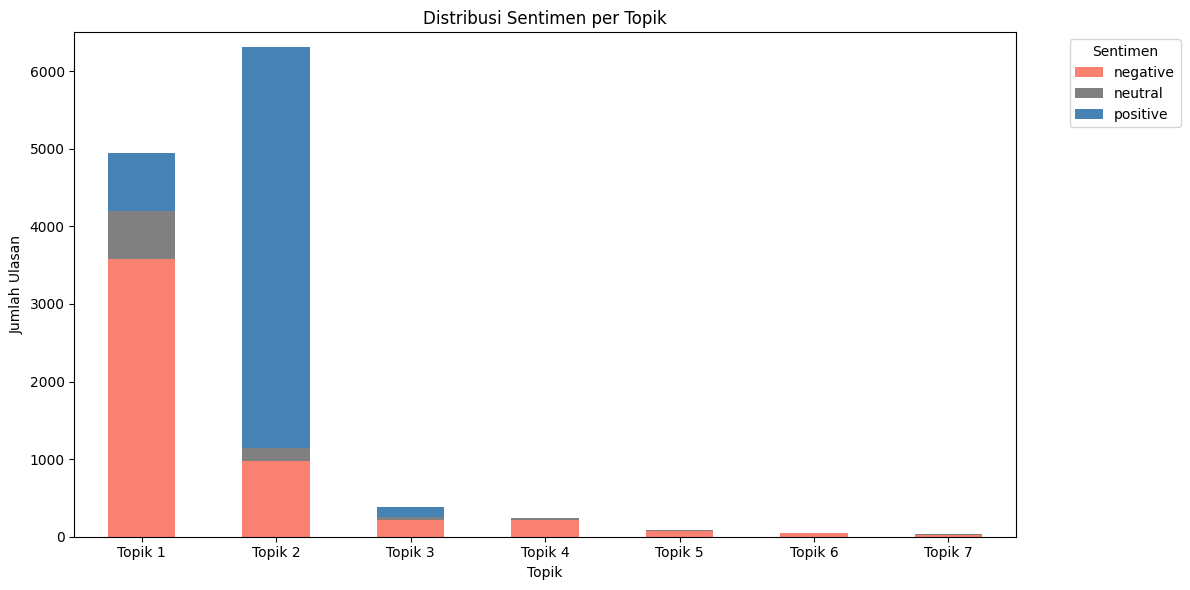

In [ ]:
sent_topic = pd.crosstab(df_integrated_clean["topic_name"], df_integrated_clean["pred_label_baseline"])

# 2. Ubah index (nama topik yang panjang) menjadi "Topik 1", "Topik 2", dst.
sent_topic.index = [f"Topik {i+1}" for i in range(len(sent_topic))]

# 3. Plotting
ax = sent_topic.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color={c: col for c, col in zip(["positive", "neutral", "negative"], ["steelblue", "gray", "salmon"])
           if c in sent_topic.columns}
)

plt.title("Distribusi Sentimen per Topik")
plt.xlabel("Topik")
plt.ylabel("Jumlah Ulasan")

# 4. Atur batas sumbu Y ke 10.000
plt.ylim(0, 6500)

# Opsional: Memperjelas tampilan label X
plt.xticks(rotation=0, ha="center")

plt.legend(title="Sentimen", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

# Simpan dan Tampilkan
plt.savefig(FIGURES_PATH + "sentiment_per_topik.png", dpi=300, bbox_inches="tight")
plt.show()

Starting Word Cloud and Frequent Words Distribution visualization...

--- Processing Sentiment: Positive ---
Word Cloud for 'Positive' sentiment saved to: /content/drive/My Drive/Colab Notebooks/Penelitian/Figures/wordcloud_sentiment_positive.png


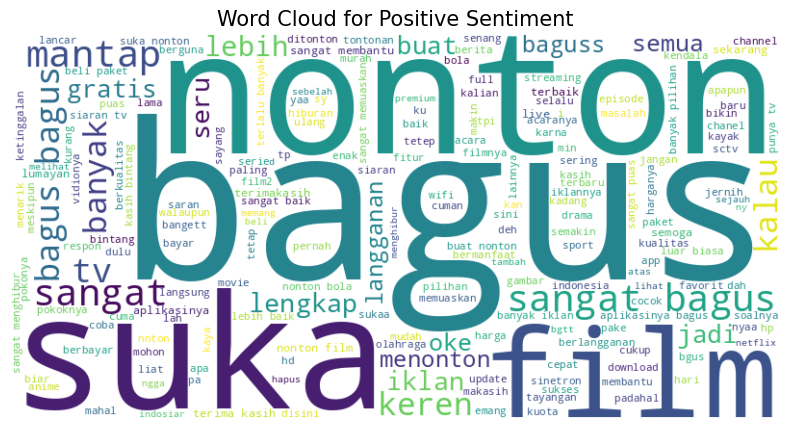

Frequent words plot for 'Positive' sentiment saved to: /content/drive/My Drive/Colab Notebooks/Penelitian/Figures/frequent_words_sentiment_positive.png


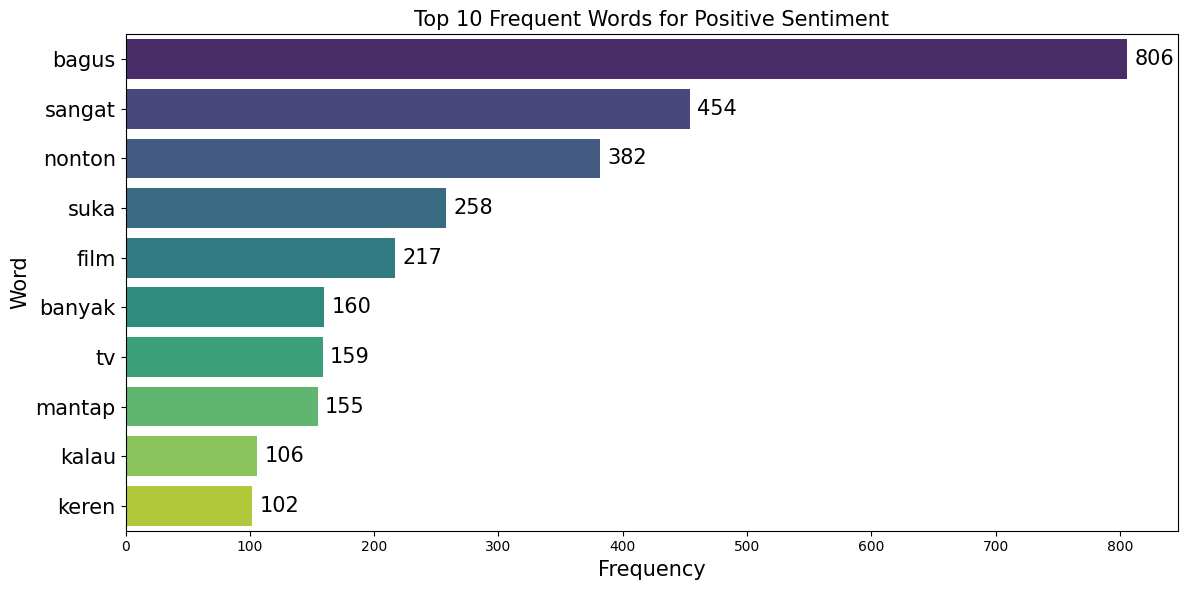


--- Processing Sentiment: Negative ---
Word Cloud for 'Negative' sentiment saved to: /content/drive/My Drive/Colab Notebooks/Penelitian/Figures/wordcloud_sentiment_negative.png


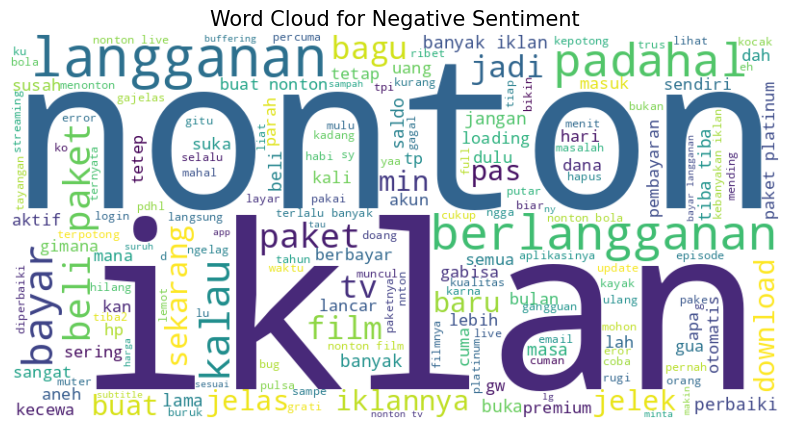

Frequent words plot for 'Negative' sentiment saved to: /content/drive/My Drive/Colab Notebooks/Penelitian/Figures/frequent_words_sentiment_negative.png


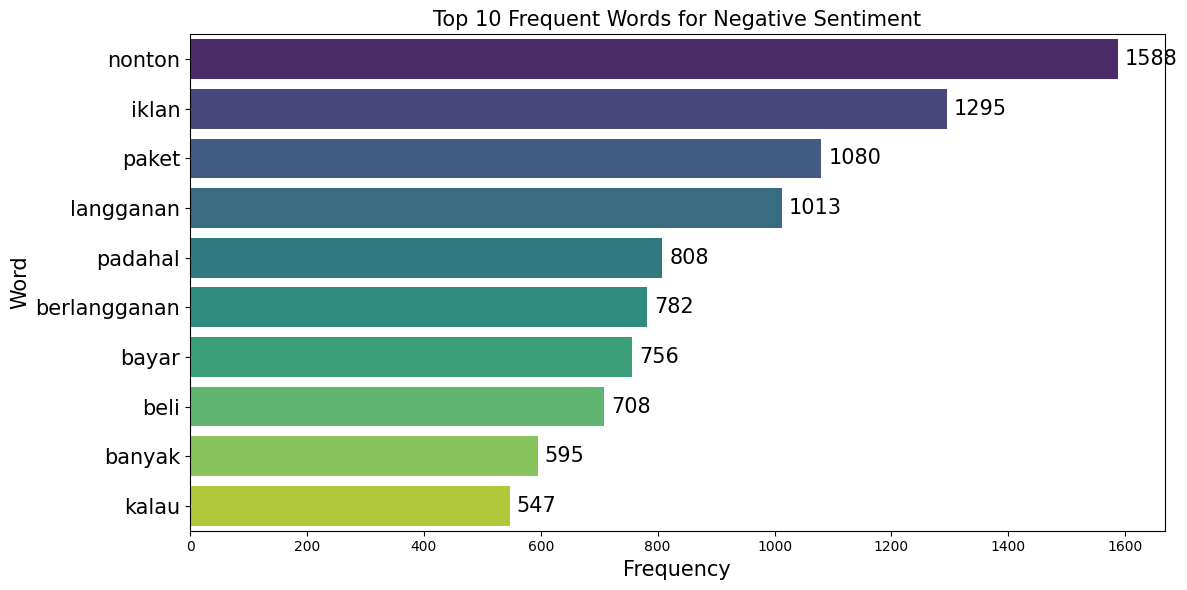


--- Processing Sentiment: Neutral ---
Word Cloud for 'Neutral' sentiment saved to: /content/drive/My Drive/Colab Notebooks/Penelitian/Figures/wordcloud_sentiment_neutral.png


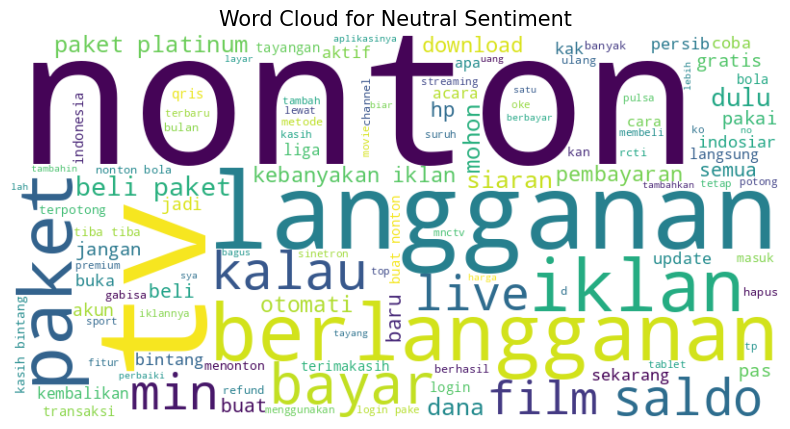

Frequent words plot for 'Neutral' sentiment saved to: /content/drive/My Drive/Colab Notebooks/Penelitian/Figures/frequent_words_sentiment_neutral.png


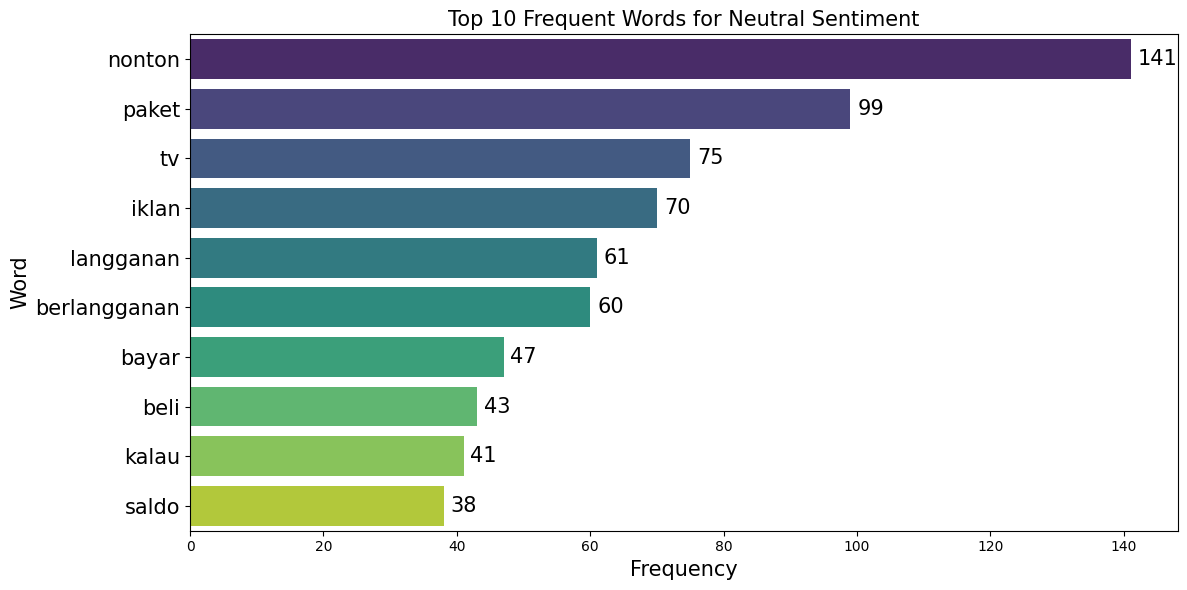


Word Cloud and Frequent Words Distribution visualization completed.


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# Pastikan BASE_PATH dan FIGURES_PATH sudah terdefinisi dari sel sebelumnya
# BASE_PATH = "/content/drive/My Drive/Colab Notebooks/Penelitian/"
# FIGURES_PATH = BASE_PATH + "Figures/"

# Install wordcloud jika belum ada
try:
    from wordcloud import WordCloud
except ImportError:
    print("Menginstall library 'wordcloud'...")
    !pip install -q wordcloud
    from wordcloud import WordCloud

# Load data sentimen
df_sentiment_baseline = pd.read_csv(BASE_PATH + "data_baseline_sentiment.csv")

# Siapkan stopwords (re-definisi untuk self-containment)
factory_sw         = StopWordRemoverFactory()
stopwords_sastrawi = set(factory_sw.get_stop_words())
custom_stopwords   = {
    "video", "tonton", "aplikasi", "vidio", "nya", "banget", "sih", "dong",
    "nih", "ya", "aja", "the", "best", "good", "job", "aku", "kok", "gak",
    "mau", "terus", "malah", "ni", "apk", "udh", "sama", "sekali", "si", "pencari", "tuhan"
}
ALL_STOPWORDS = list(stopwords_sastrawi.union(custom_stopwords))

def generate_wordcloud(text_series, sentiment_label, filename):
    """Generates and displays a word cloud for a given sentiment."""
    if text_series.empty:
        print(f"No text for '{sentiment_label}' sentiment to generate word cloud.")
        return

    text = " ".join(text_series.dropna().astype(str))
    if not text.strip():
        print(f"Empty text for '{sentiment_label}' sentiment to generate word cloud.")
        return

    wordcloud = WordCloud(
        width=800, height=400,
        background_color='white',
        stopwords=ALL_STOPWORDS,
        min_font_size=10
    ).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for {sentiment_label.capitalize()} Sentiment', fontsize=15)
    save_path = os.path.join(FIGURES_PATH, filename)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Word Cloud for '{sentiment_label.capitalize()}' sentiment saved to: {save_path}")
    plt.show()

def plot_frequent_words(text_series, sentiment_label, n_words=10, filename=""):
    """Plots the distribution of frequent words for a given sentiment."""
    if text_series.empty:
        print(f"No text for '{sentiment_label}' sentiment to analyze frequent words.")
        return

    vectorizer = CountVectorizer(stop_words=ALL_STOPWORDS)
    X = vectorizer.fit_transform(text_series.dropna().astype(str))
    word_freq = pd.DataFrame(
        {'word': vectorizer.get_feature_names_out(), 'frequency': X.sum(axis=0).tolist()[0]}
    )
    word_freq = word_freq.sort_values(by='frequency', ascending=False).head(n_words)

    if word_freq.empty:
        print(f"No frequent words found for '{sentiment_label}' sentiment.")
        return

    plt.figure(figsize=(12, 6))
    ax = sns.barplot(x='frequency', y='word', data=word_freq, palette='viridis')
    plt.title(f'Top {n_words} Frequent Words for {sentiment_label.capitalize()} Sentiment', fontsize=15)
    plt.xlabel('Frequency', fontsize=15)
    plt.ylabel('Word', fontsize=15)

    # Add total count on top of each bar
    for container in ax.containers:
        ax.bar_label(container, fmt='%d', padding=5, fontsize=15)

    plt.yticks(fontsize=15) # Set font size for y-axis labels

    plt.tight_layout()
    save_path = os.path.join(FIGURES_PATH, filename)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Frequent words plot for '{sentiment_label.capitalize()}' sentiment saved to: {save_path}")
    plt.show()

print("Starting Word Cloud and Frequent Words Distribution visualization...")

# Process each sentiment label
for sentiment in ["positive", "negative", "neutral"]:
    df_filtered = df_sentiment_baseline[df_sentiment_baseline["pred_label_baseline"] == sentiment]
    text_data = df_filtered["text_baseline_sentiment"]

    print(f"\n--- Processing Sentiment: {sentiment.capitalize()} ---")

    # Generate Word Cloud
    wc_filename = f"wordcloud_sentiment_{sentiment}.png"
    generate_wordcloud(text_data, sentiment, wc_filename)

    # Plot Frequent Words
    fw_filename = f"frequent_words_sentiment_{sentiment}.png"
    plot_frequent_words(text_data, sentiment, filename=fw_filename)

print("\nWord Cloud and Frequent Words Distribution visualization completed.")

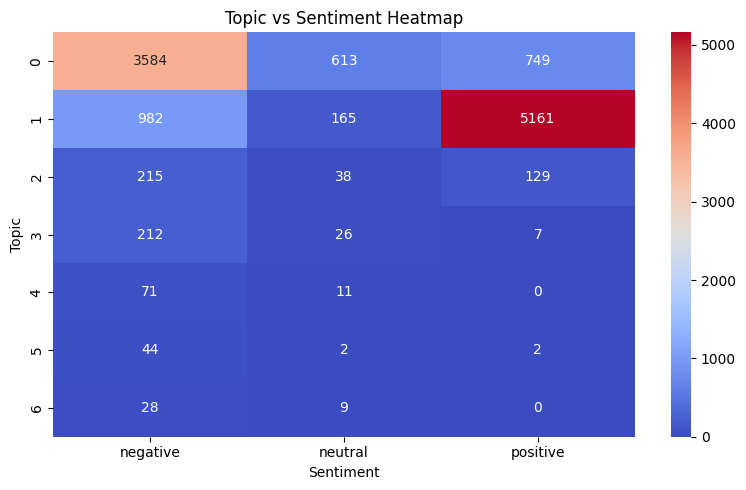

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv(BASE_PATH + "Integrasi_aplikasi_vidio.csv")

# Misal kolom: topic_name dan pred_label_baseline (sesuaikan kalau beda)
# Ambil hanya nomor topik (1,2,3,...)
df["topic_short"] = df["topic_name"].str.extract(r'^(\d+)')

# Buat tabel silang (topic vs sentiment)
sent_topic = pd.crosstab(df["topic_short"], df["pred_label_baseline"])

# Plot heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(sent_topic, annot=True, fmt="d", cmap="coolwarm")

plt.title("Topic vs Sentiment Heatmap")
plt.xlabel("Sentiment")
plt.ylabel("Topic")

plt.tight_layout()
plt.savefig(FIGURES_PATH + "heatmap_topic_sentiment.png", dpi=300, bbox_inches="tight")
plt.show()

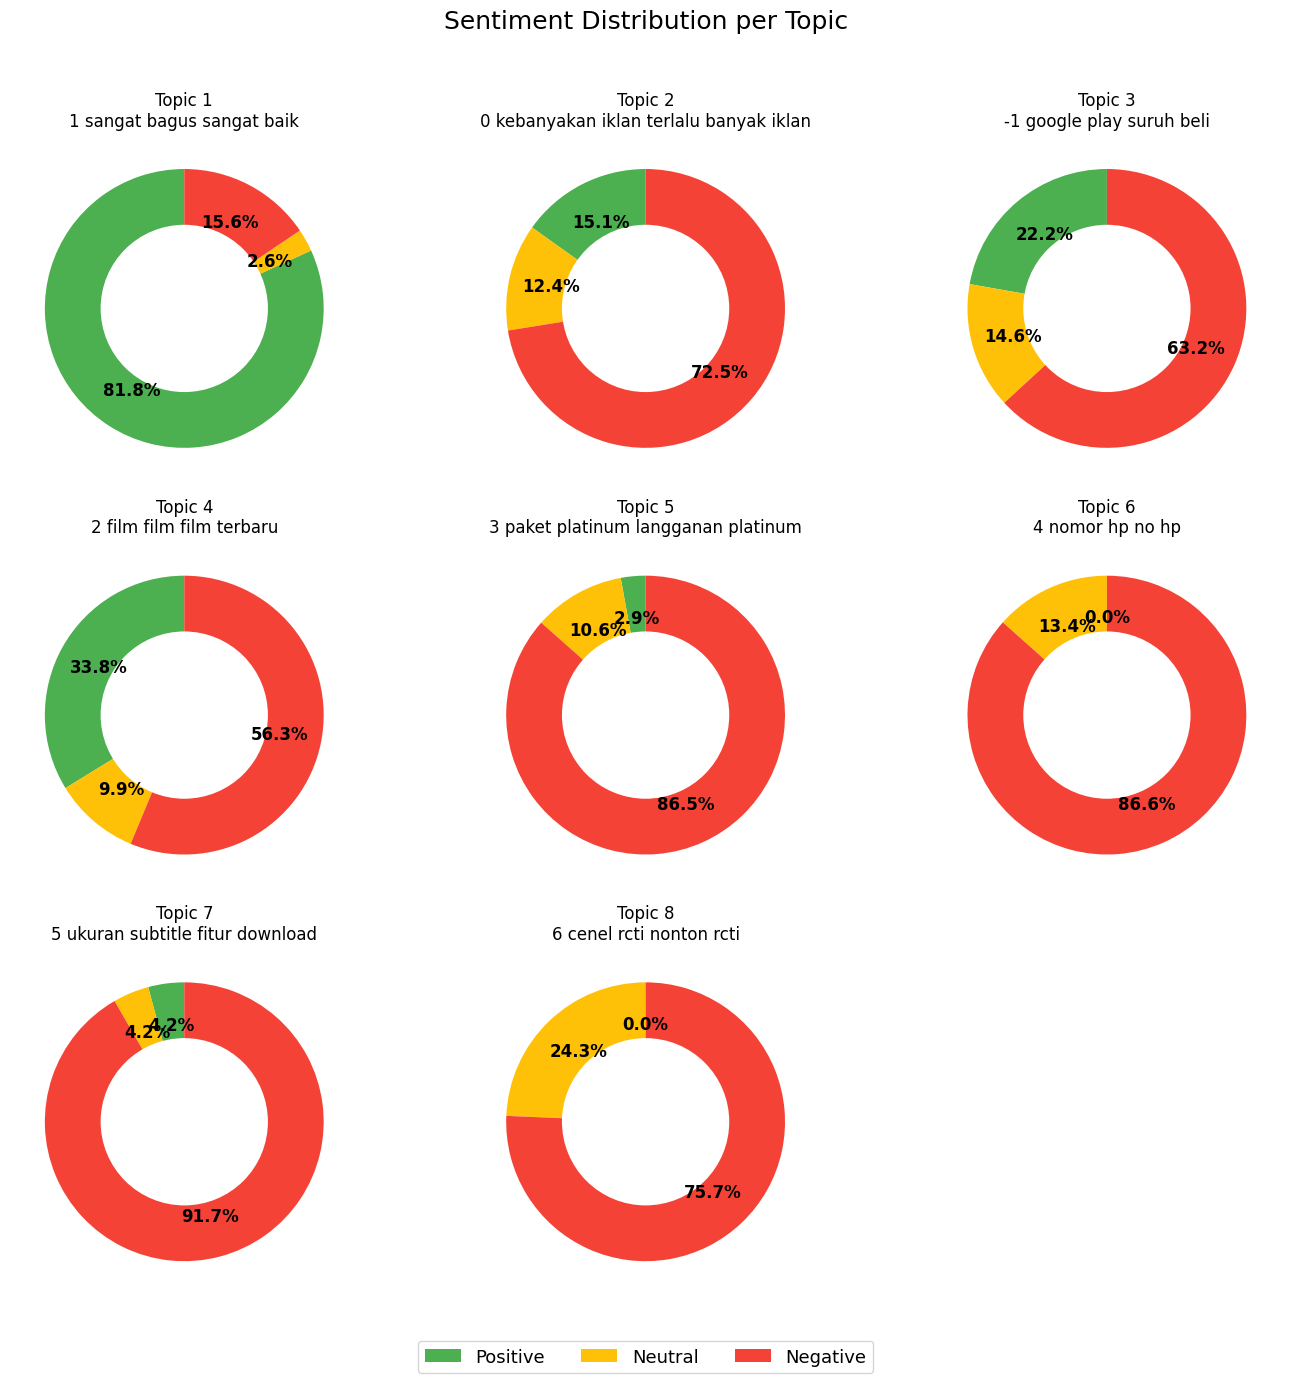

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv(BASE_PATH + "Integrasi_aplikasi_vidio.csv")

# Ambil top 9 topik
top_topics = df["topic_name"].value_counts().head(9).index

# Warna kontras & konsisten
color_map = {
    "positive": "#4CAF50",
    "neutral": "#FFC107",
    "negative": "#F44336"
}

# Canvas 3x3
fig, axes = plt.subplots(3, 3, figsize=(14, 14))
axes = axes.flatten()

for i, topic in enumerate(top_topics):
    ax = axes[i]
    subset = df[df["topic_name"] == topic]
    sent_counts = subset["pred_label_baseline"].value_counts()

    # Urutan konsisten
    sent_counts = sent_counts.reindex(["positive", "neutral", "negative"]).fillna(0)
    colors = [color_map[s] for s in sent_counts.index]

    wedges, texts, autotexts = ax.pie(
        sent_counts,
        labels=None,
        autopct='%1.1f%%',
        startangle=90,
        colors=colors,
        pctdistance=0.7,  # posisi persen (lebih ke tengah)
        textprops={
            'fontsize': 12,
            'weight': 'bold',
            'color': 'black'
        }
    )

    # Donut
    centre_circle = plt.Circle((0, 0), 0.6, fc='white')
    ax.add_artist(centre_circle)

    # Judul pendek
    short_label = " ".join(topic.split("_")[:3])
    ax.set_title(f"Topic {i+1}\n{short_label}", fontsize=12)

# Hapus subplot kosong kalau ada
for j in range(len(top_topics), len(axes)):
    fig.delaxes(axes[j])

# Legend global
fig.legend(
    ["Positive", "Neutral", "Negative"],
    loc="lower center",
    ncol=3,
    fontsize=13
)

plt.suptitle("Sentiment Distribution per Topic", fontsize=18)

plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.savefig(FIGURES_PATH + "pie_topic_3x3.png", dpi=300)
plt.show()

Graph saved at: /content/drive/My Drive/Colab Notebooks/Penelitian/Figures/distribusi_rating_filter.png


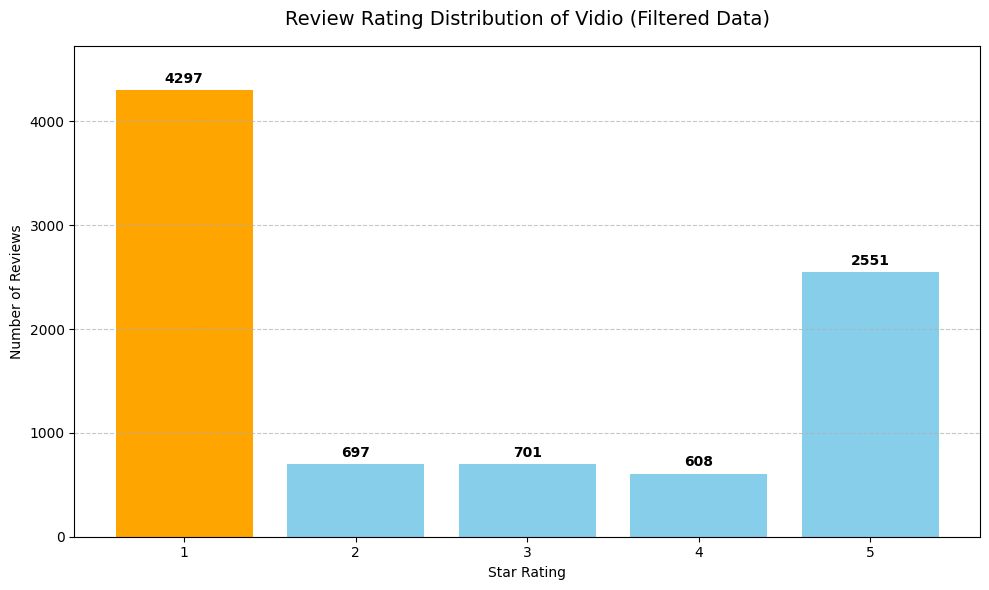


Example of 5 Filtered Data Rows:


,text,rating,date
0,"mau nonton bola malah eror,mending siarin boke...",1,2026-03-31 20:28:46
1,Kntol. Setelah langganan malah jelek kualitas ...,1,2026-03-31 19:45:17
2,VIDEO SPORTS MOVIE SERTS,5,2026-03-31 18:25:53
3,min saya pengguna kartu xl dan ada gratis vidi...,5,2026-03-31 15:21:48
4,jujur emng bnyk film tapi ada film kesukaan sy...,2,2026-03-31 12:56:59


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from google.colab import drive

def plot_distribution(df, title, filename):
    """Visualisasi distribusi rating dan simpan ke FIGURES_PATH."""
    rating_counts = df["rating"].value_counts().sort_index()
    max_val       = rating_counts.max()
    colors        = ["orange" if v == max_val else "skyblue" for v in rating_counts]

    plt.figure(figsize=(10, 6))
    bars = plt.bar(rating_counts.index, rating_counts.values, color=colors)
    plt.bar_label(bars, padding=3, fontsize=10, fontweight="bold")

    # Label dalam Bahasa Inggris
    plt.title(title, fontsize=14, pad=15)
    plt.xlabel("Star Rating")
    plt.ylabel("Number of Reviews")

    plt.xticks(rating_counts.index)
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.ylim(0, max_val * 1.1)
    plt.tight_layout()

    # Menyimpan grafik ke folder Figures di GDrive
    save_path = os.path.join(FIGURES_PATH, filename)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Graph saved at: {save_path}")
    plt.show()

# --- Eksekusi Program Utama ---
try:
    # Asumsi file CSV Anda juga berada di dalam folder BASE_PATH
    csv_file_path = os.path.join(BASE_PATH, "data_filter_vidio.csv")

    # Load data CSV
    df_filter = pd.read_csv(csv_file_path)

    # Visualisasikan menggunakan fungsi
    plot_distribution(
        df_filter,
        "Review Rating Distribution of Vidio (Filtered Data)",
        "distribusi_rating_filter.png"
    )

    # Tampilkan 5 data teratas (menggunakan display karena di Colab)
    print("\nExample of 5 Filtered Data Rows:")
    display(df_filter.head(5))

except FileNotFoundError:
    print(f"Error: File CSV tidak ditemukan.")
    print(f"Pastikan 'data_filter_vidio.csv' sudah di-upload ke: {BASE_PATH}")
except KeyError:
    print("Error: Kolom 'rating' tidak ditemukan di dalam CSV. Cek kembali nama kolom Anda.")

In [ ]:
import pandas as pd

# Load the saved dataset
file_path = BASE_PATH + "data_baseline_sentiment.csv"
df_check = pd.read_csv(file_path)

# 1. Count the occurrences of each class
# Assuming your column is named 'label' (adjust if it's 'sentiment' or 'rating')
sentiment_counts = df_check['pred_label_baseline'].value_counts().reset_index()

# 2. Rename columns for the English table
sentiment_counts.columns = ['Sentiment Class', 'Total Count']

# 3. Calculate percentage for better insight
total = sentiment_counts['Total Count'].sum()
sentiment_counts['Percentage'] = (sentiment_counts['Total Count'] / total * 100).round(2).astype(str) + '%'

# 4. Display the table
print("\n" + "="*35)
print("SENTIMENT DISTRIBUTION SUMMARY")
print("="*35)
print(sentiment_counts.to_string(index=False))
print("="*35)
print(f"Total Records: {total}")


SENTIMENT DISTRIBUTION SUMMARY
Sentiment Class  Total Count Percentage
       negative         5972     67.45%
       positive         2052     23.18%
        neutral          830      9.37%
Total Records: 8854


In [ ]:
import pandas as pd

# Pastikan variabel BASE_PATH sudah didefinisikan sebelumnya
file_path = BASE_PATH + "data_preprocessed_vidio.csv"

# Memuat dataset
df = pd.read_csv(file_path)

# Menampilkan 5 baris terakhir di konsol
df.tail()

,original_filter,rating,date,case_folding,url_removal,slang_normalization,repeated_char_removal
8849,bagus tapi siaran RCTI nya tidak ada,4,2025-04-01 07:14:29,bagus tapi siaran rcti nya tidak ada,bagus tapi siaran rcti nya tidak ada,bagus tapi siaran rcti nya tidak ada,bagus tapi siaran rcti nya tidak ada
8850,Terimakasih untuk yang membuat aplikasi vidio ...,5,2025-04-01 07:07:35,terimakasih untuk yang membuat aplikasi vidio ...,terimakasih untuk yang membuat aplikasi vidio ...,terimakasih untuk yang membuat aplikasi vidio ...,terimakasih untuk yang membuat aplikasi vidio ...
8851,"coba aja nggk ada vidio premium,pasti saya non...",1,2025-04-01 06:52:52,"coba aja nggk ada vidio premium,pasti saya non...","coba aja nggk ada vidio premium,pasti saya non...","coba aja nggk ada vidio premium,pasti saya non...","coba aja nggk ada vidio premium,pasti saya non..."
8852,aplikasi video ini seru karena bisa nonton apa...,5,2025-04-01 04:24:00,aplikasi video ini seru karena bisa nonton apa...,aplikasi video ini seru karena bisa nonton apa...,aplikasi video ini seru karena bisa nonton apa...,aplikasi video ini seru karena bisa nonton apa...
8853,burik kli nih apk mangkin lama mau nyari untun...,1,2025-04-01 00:28:20,burik kli nih apk mangkin lama mau nyari untun...,burik kli nih apk mangkin lama mau nyari untun...,burik kli nih aplikasi mangkin lama mau nyari ...,burik kli nih aplikasi mangkin lama mau nyari ...


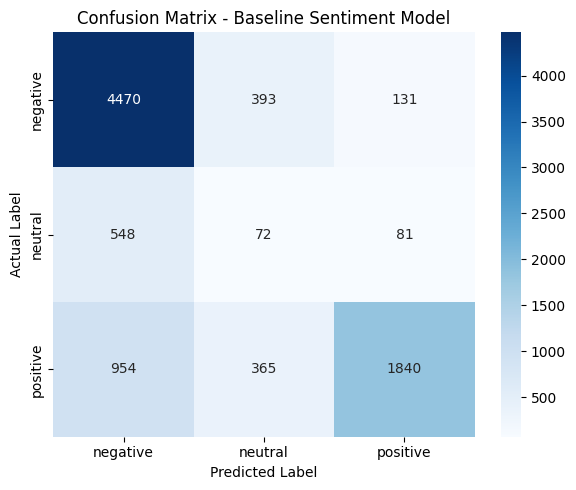

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Load dataset hasil baseline
df = pd.read_csv(BASE_PATH + "data_baseline_sentiment.csv")

# 2. Ambil label
y_true = df["actual_label"]
y_pred = df["pred_label_baseline"]

# 3. Tentukan urutan label (biar konsisten)
labels = ["negative", "neutral", "positive"]

# 4. Hitung confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)

# 5. Visualisasi
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels,
            yticklabels=labels)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Baseline Sentiment Model")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Load data
df = pd.read_csv(BASE_PATH + "Integrasi_aplikasi_vidio.csv")

# Pastikan kolom yang dipakai benar
# Ganti ini kalau nama kolom berbeda
topic_col = "topic_name"
sentiment_col = "pred_label_baseline"   # atau "actual_label" kalau mau ground truth

# Grouping + pivot
table = (
    df.groupby([topic_col, sentiment_col])
      .size()
      .unstack(fill_value=0)
)

# Pastikan urutan kolom konsisten
table = table.reindex(columns=["negative", "neutral", "positive"], fill_value=0)

# Tambah total
table["Total"] = table.sum(axis=1)

# Reset index biar rapi
table = table.reset_index()

# Tampilkan
print(table)

# Optional: simpan
table.to_csv(BASE_PATH + "topic_sentiment_summary.csv", index=False)

pred_label_baseline                                         topic_name  \
0                    -1_google play_suruh beli_live streaming_saldo...   
1                    0_kebanyakan iklan_terlalu banyak iklan_nonton...   
2                    1_sangat bagus_sangat baik_bagus sangat_premie...   
3                    2_film film_film terbaru_drama korea_liga indo...   
4                    3_paket platinum_langganan platinum_platinum e...   
5                               4_nomor hp_no hp_login pake_pake no hp   
6                    5_ukuran subtitle_fitur download_besar kecil_d...   
7                    6_cenel rcti_nonton rcti_channel tv_bagus cuma...   

pred_label_baseline  negative  neutral  positive  Total  
0                        1684      390       592   2666  
1                        3584      613       749   4946  
2                         982      165      5161   6308  
3                         215       38       129    382  
4                         212       26     

In [ ]:
df = pd.read_csv(BASE_PATH + "Integrasi_aplikasi_vidio.csv")

print("Total rows:", len(df))

# cek duplicate full row
print("Duplicate rows:", df.duplicated().sum())

# cek duplicate berdasarkan teks (lebih penting)
print("Duplicate text:", df["text_baseline_sentiment"].duplicated().sum())

Total rows: 14714
Duplicate rows: 5649
Duplicate text: 6313


In [ ]:
df_base = pd.read_csv(BASE_PATH + "data_preprocessed_vidio.csv")
df_topic = pd.read_csv(BASE_PATH + "Optimasi_BERTopic_vidio.csv")
df_sent = pd.read_csv(BASE_PATH + "data_baseline_sentiment.csv")

# reset index untuk jaga konsistensi
df_base = df_base.reset_index(drop=True)
df_topic = df_topic.reset_index(drop=True)
df_sent = df_sent.reset_index(drop=True)

# buat ID
df_base["id"] = df_base.index
df_topic["id"] = df_topic.index
df_sent["id"] = df_sent.index

In [ ]:
df_base.head(5)

,original_filter,rating,date,case_folding,url_removal,slang_normalization,repeated_char_removal,id
0,"mau nonton bola malah eror,mending siarin boke...",1,2026-03-31 20:28:46,"mau nonton bola malah eror,mending siarin boke...","mau nonton bola malah eror,mending siarin boke...","mau nonton bola malah eror,mending siarin boke...","mau nonton bola malah eror,mending siarin boke...",0
1,Kntol. Setelah langganan malah jelek kualitas ...,1,2026-03-31 19:45:17,kntol. setelah langganan malah jelek kualitas ...,kntol. setelah langganan malah jelek kualitas ...,kntol. setelah langganan malah jelek kualitas ...,kntol. setelah langganan malah jelek kualitas ...,1
2,VIDEO SPORTS MOVIE SERTS,5,2026-03-31 18:25:53,video sports movie serts,video sports movie serts,video sports movie serts,video sports movie serts,2
3,min saya pengguna kartu xl dan ada gratis vidi...,5,2026-03-31 15:21:48,min saya pengguna kartu xl dan ada gratis vidi...,min saya pengguna kartu xl dan ada gratis vidi...,min saya pengguna kartu xl dan ada gratis vidi...,min saya pengguna kartu xl dan ada gratis vidi...,3
4,jujur emng bnyk film tapi ada film kesukaan sy...,2,2026-03-31 12:56:59,jujur emng bnyk film tapi ada film kesukaan sy...,jujur emng bnyk film tapi ada film kesukaan sy...,jujur emng bnyk film tapi ada film kesukaan sy...,jujur emng bnyk film tapi ada film kesukaan sy...,4


In [ ]:
df_topic.head(5)

,original_filter,rating,date,case_folding,url_removal,slang_normalization,repeated_char_removal,clean_base_bertopic,topic,id
0,"mau nonton bola malah eror,mending siarin boke...",1,2026-03-31 20:28:46,"mau nonton bola malah eror,mending siarin boke...","mau nonton bola malah eror,mending siarin boke...","mau nonton bola malah eror,mending siarin boke...","mau nonton bola malah eror,mending siarin boke...","mau nonton bola malah eror,mending siarin boke...",1,0
1,Kntol. Setelah langganan malah jelek kualitas ...,1,2026-03-31 19:45:17,kntol. setelah langganan malah jelek kualitas ...,kntol. setelah langganan malah jelek kualitas ...,kntol. setelah langganan malah jelek kualitas ...,kntol. setelah langganan malah jelek kualitas ...,kntol. setelah langganan malah jelek kualitas ...,2,1
2,VIDEO SPORTS MOVIE SERTS,5,2026-03-31 18:25:53,video sports movie serts,video sports movie serts,video sports movie serts,video sports movie serts,video sports movie serts,0,2
3,min saya pengguna kartu xl dan ada gratis vidi...,5,2026-03-31 15:21:48,min saya pengguna kartu xl dan ada gratis vidi...,min saya pengguna kartu xl dan ada gratis vidi...,min saya pengguna kartu xl dan ada gratis vidi...,min saya pengguna kartu xl dan ada gratis vidi...,min saya pengguna kartu xl dan ada gratis vidi...,-1,3
4,jujur emng bnyk film tapi ada film kesukaan sy...,2,2026-03-31 12:56:59,jujur emng bnyk film tapi ada film kesukaan sy...,jujur emng bnyk film tapi ada film kesukaan sy...,jujur emng bnyk film tapi ada film kesukaan sy...,jujur emng bnyk film tapi ada film kesukaan sy...,jujur emng bnyk film tapi ada film kesukaan sy...,2,4


In [ ]:
df_sent.head(5)

,original_filter,rating,date,case_folding,url_removal,slang_normalization,repeated_char_removal,text_baseline_sentiment,actual_label,pred_label_baseline,id
0,"mau nonton bola malah eror,mending siarin boke...",1,2026-03-31 20:28:46,"mau nonton bola malah eror,mending siarin boke...","mau nonton bola malah eror,mending siarin boke...","mau nonton bola malah eror,mending siarin boke...","mau nonton bola malah eror,mending siarin boke...","mau nonton bola malah eror,mending siarin boke...",negative,negative,0
1,Kntol. Setelah langganan malah jelek kualitas ...,1,2026-03-31 19:45:17,kntol. setelah langganan malah jelek kualitas ...,kntol. setelah langganan malah jelek kualitas ...,kntol. setelah langganan malah jelek kualitas ...,kntol. setelah langganan malah jelek kualitas ...,kntol. setelah langganan malah jelek kualitas ...,negative,negative,1
2,VIDEO SPORTS MOVIE SERTS,5,2026-03-31 18:25:53,video sports movie serts,video sports movie serts,video sports movie serts,video sports movie serts,video sports movie serts,positive,neutral,2
3,min saya pengguna kartu xl dan ada gratis vidi...,5,2026-03-31 15:21:48,min saya pengguna kartu xl dan ada gratis vidi...,min saya pengguna kartu xl dan ada gratis vidi...,min saya pengguna kartu xl dan ada gratis vidi...,min saya pengguna kartu xl dan ada gratis vidi...,min saya pengguna kartu xl dan ada gratis vidi...,positive,negative,3
4,jujur emng bnyk film tapi ada film kesukaan sy...,2,2026-03-31 12:56:59,jujur emng bnyk film tapi ada film kesukaan sy...,jujur emng bnyk film tapi ada film kesukaan sy...,jujur emng bnyk film tapi ada film kesukaan sy...,jujur emng bnyk film tapi ada film kesukaan sy...,jujur emng bnyk film tapi ada film kesukaan sy...,negative,negative,4


In [ ]:
df_merge = df_base.merge(df_topic[["id", "topic"]], on="id") \
                  .merge(df_sent[["id", "pred_label_baseline"]], on="id")

In [ ]:
print(len(df_merge))  # harus 8854
print(df_merge["id"].duplicated().sum())  # harus 0

8854
0


In [ ]:
df_merge.to_csv(BASE_PATH + "primary_key_integrated.csv", index=False)

In [ ]:
# Insight distribusi sentimen per topik (tanpa outlier)
insight = df_integrated_clean.groupby(["topic_name", "pred_label_baseline"]).size().unstack(fill_value=0)
if not insight.empty:
    insight["Total"] = insight.sum(axis=1)
    insight = insight.sort_values(by="Total", ascending=False)

In [ ]:
import pandas as pd

# load hasil merge clean
df = pd.read_csv(BASE_PATH + "primary_key_integrated.csv")

# grouping
insight = (
    df.groupby(["topic", "pred_label_baseline"])
      .size()
      .unstack(fill_value=0)
)

# tambah total + sorting
if not insight.empty:
    insight["Total"] = insight.sum(axis=1)
    insight = insight.sort_values(by="Total", ascending=False)

print(insight)

pred_label_baseline  negative  neutral  positive  Total
topic                                                  
 0                       2869      363       685   3917
-1                       1641      219       451   2311
 1                        892      162       780   1834
 2                        215       38       127    380
 3                        212       26         7    245
 4                         71       11         0     82
 5                         44        2         2     48
 6                         28        9         0     37
